<a href="https://colab.research.google.com/github/luisy-eng/ECE491_Lab3/blob/main/ECE4_Lab3_BackdoorBox_Upload_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ECE4 Lab 3 — BackdoorBox



## 1. Check runtime

In [1]:
import sys, torch
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available(): print("GPU:", torch.cuda.get_device_name(0))

Python: 3.13.16
PyTorch: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


## 2. Upload `BackdoorBox-main.zip`

Click **Choose Files** and select the ZIP you downloaded from GitHub. If your Colab session restarts, run the upload cell again (or save the ZIP in Google Drive).

In [2]:
from google.colab import files
uploaded = files.upload()
zip_names = [name for name in uploaded if name.lower().endswith(".zip")]
assert len(zip_names) == 1, "Upload exactly one repository ZIP file."
zip_name = zip_names[0]
print("Uploaded:", zip_name)

Saving BackdoorBox-main.zip to BackdoorBox-main.zip
Uploaded: BackdoorBox-main.zip


## 3. Extract to `/content/BackdoorBox-main`

In [3]:
from pathlib import Path
import zipfile
import shutil

root = Path("/content")
project = root / "BackdoorBox-main"
if project.exists():
    shutil.rmtree(project)

with zipfile.ZipFile(zip_name) as z:
    members = z.namelist()
    assert all(not Path(m).is_absolute() and ".." not in Path(m).parts for m in members), "Unsafe ZIP paths"
    z.extractall(root)

assert (project / "core" / "__init__.py").exists(), "Expected BackdoorBox-main/core not found. Check ZIP layout."
print("Extracted:", project)
print("Attack samples:", [p.name for p in sorted((project / "core" / "attacks").glob("*.py")) if p.name in ("BadNets.py", "Blended.py", "LabelConsistent.py")])

Extracted: /content/BackdoorBox-main
Attack samples: ['BadNets.py', 'Blended.py', 'LabelConsistent.py']


## 4. Install baseline libraries without downgrading Colab PyTorch

**Do not run `pip install -r requirements.txt`**. This repository pins PyTorch 1.8.0 and CUDA 11.1, which are incompatible with current Colab runtimes. Its `core` imports may also require more optional packages; we will diagnose these after the baseline setup.

In [4]:
%pip -q install lpips imageio matplotlib scikit-learn pandas opencv-python-headless

## 5. Set Python path and inspect framework imports

In [5]:
import os, sys, importlib, traceback
os.chdir(project)
if str(project) not in sys.path:
    sys.path.insert(0, str(project))
print("Working directory:", os.getcwd())

try:
    import core
    print("BackdoorBox core imported successfully")
    for name in ("BadNets", "Blended", "LabelConsistent", "FineTuning", "Pruning"):
        print(f"{name}: {hasattr(core, name)}")
except Exception as exc:
    print("BackdoorBox import requires compatibility work:")
    print(type(exc).__name__ + ":", exc)
    print("This does not mean your upload failed. Save the full error for the next step.")
    traceback.print_exc(limit=5)

Working directory: /content/BackdoorBox-main
BackdoorBox import requires compatibility work:
ImportError: cannot import name 'zero_gradients' from 'torch.autograd.gradcheck' (/usr/local/lib/python3.13/dist-packages/torch/autograd/gradcheck.py)
This does not mean your upload failed. Save the full error for the next step.


/content/BackdoorBox-main/core/attacks/Blind.py:209: SyntaxWarning: invalid escape sequence '\s'
  ie. min_c |\sum c_i x_i|_2^2 st. \sum c_i = 1 , 1 >= c_1 >= 0
/content/BackdoorBox-main/core/attacks/Blind.py:243: SyntaxWarning: invalid escape sequence '\s'
  Given y, it solves argmin_z |y-z|_2 st \sum z = 1 , 1 >= z_i >= 0 for all i
/content/BackdoorBox-main/core/attacks/Blind.py:278: SyntaxWarning: invalid escape sequence '\s'
  element in the convex hull as min |u|_2 st. u = \sum c_i vecs[i]
/content/BackdoorBox-main/core/attacks/Blind.py:333: SyntaxWarning: invalid escape sequence '\s'
  as min |u|_2 st. u = \sum c_i vecs[i] and \sum c_i = 1.
Traceback (most recent call last):
  File "/tmp/ipykernel_2686/949600075.py", line 8, in <cell line: 0>
    import core
  File "/content/BackdoorBox-main/core/__init__.py", line 1, in <module>
    from .attacks import *
  File "/content/BackdoorBox-main/core/attacks/__init__.py", line 12, in <module>
    from .TUAP import TUAP
  File "/content

## 6. Load CIFAR-10 with torchvision

This creates the official training and testing datasets under `/content/data`. We will use a single consistent split for the attack comparisons.

In [6]:
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform = transforms.ToTensor()
trainset = datasets.CIFAR10(root="/content/data", train=True, download=True, transform=transform)
testset = datasets.CIFAR10(root="/content/data", train=False, download=True, transform=transform)
print("Train images:", len(trainset))
print("Test images:", len(testset))
print("Class labels:", trainset.classes)

100%|██████████| 170M/170M [31:49<00:00, 89.3kB/s]


Train images: 50000
Test images: 10000
Class labels: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 7. Display clean CIFAR-10 samples

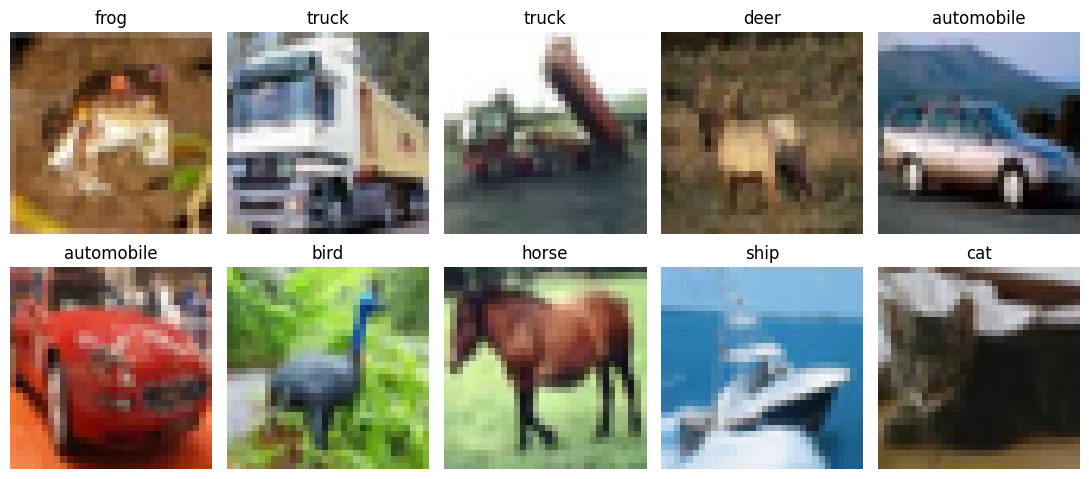

In [7]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for i, ax in enumerate(axes.flat):
    image, label = trainset[i]
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(trainset.classes[label])
    ax.axis("off")
plt.tight_layout()
plt.show()

## 8. Verify provided experiment scripts

The repository contains `Attack_BadNets.py`, `Attack_Blended.py`, and tests for `LabelConsistent`, `FineTuning`, and `Pruning`. The top-level scripts expect a folder-organized CIFAR-10 dataset, while our direct torchvision loading is simpler. We will adapt the actual experiment code after checking imports.

In [8]:
for relative in ["Attack_BadNets.py", "Attack_Blended.py", "tests/test_LabelConsistent.py", "tests/test_FineTuning.py", "tests/test_Pruning.py"]:
    p = project / relative
    print(("FOUND" if p.exists() else "MISSING"), relative)

FOUND Attack_BadNets.py
FOUND Attack_Blended.py
FOUND tests/test_LabelConsistent.py
FOUND tests/test_FineTuning.py
FOUND tests/test_Pruning.py


# Task 1 — BadNets


In [10]:
from pathlib import Path

file = Path("/content/BackdoorBox-main/core/attacks/TUAP.py")

code = file.read_text()

old = "from torch.autograd.gradcheck import zero_gradients"

new = """
def zero_gradients(x):
    if isinstance(x, torch.Tensor):
        if x.grad is not None:
            x.grad.detach_()
            x.grad.zero_()
    else:
        for item in x:
            zero_gradients(item)
"""

import torch

if old in code:
    code = code.replace(old, new)
    file.write_text(code)
    print("TUAP.py compatibility patch applied!")
else:
    print("Old import not found; file may already be patched.")

TUAP.py compatibility patch applied!


In [12]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not available")

from core.attacks.BadNets import BadNets

print("BadNets import successful!")

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
GPU: Tesla T4
BadNets import successful!


#Step 1 — Define the BadNets trigger

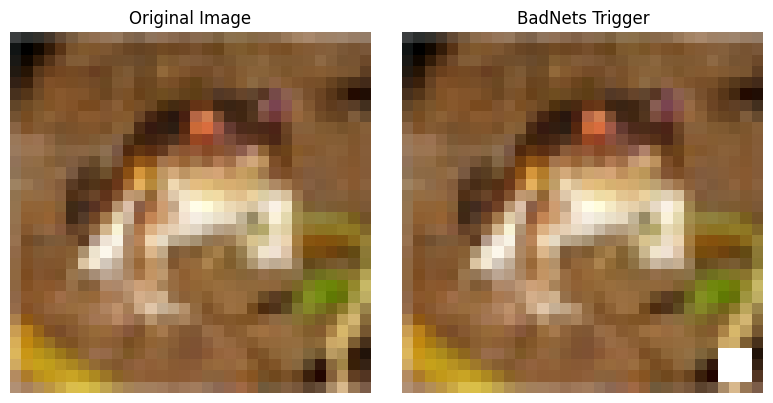

In [13]:
import torch
import matplotlib.pyplot as plt
from torchvision import datasets, transforms

# Load CIFAR-10
transform = transforms.ToTensor()

train_dataset = datasets.CIFAR10(
    root="/content/data",
    train=True,
    download=True,
    transform=transform
)

# Define a 3x3 white-square trigger
def add_badnets_trigger(image):
    poisoned = image.clone()
    poisoned[:, -4:-1, -4:-1] = 1.0
    return poisoned

# Select a sample image
image, label = train_dataset[0]
poisoned_image = add_badnets_trigger(image)

# Display clean and poisoned images
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(image.permute(1, 2, 0))
axes[0].set_title("Original Image")

axes[1].imshow(poisoned_image.permute(1, 2, 0))
axes[1].set_title("BadNets Trigger")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.savefig("badnets_sample.png", dpi=300)
plt.show()


#Step 2 — Create the poisoned dataset using BackdoorBox

In [15]:

import random
import torch
import torch.nn as nn
from torchvision import datasets, transforms, models
from core.attacks.BadNets import BadNets

# Reproducibility
random.seed(42)
torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load CIFAR-10 training and test datasets
# BackdoorBox requires transforms.Compose()
transform = transforms.Compose([
    transforms.ToTensor()
])

train_dataset = datasets.CIFAR10(
    root="/content/data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.CIFAR10(
    root="/content/data",
    train=False,
    download=True,
    transform=transform
)

# Define the BadNets trigger (3x3 white square)
pattern = torch.zeros((1, 32, 32), dtype=torch.uint8)
pattern[:, -4:-1, -4:-1] = 255

weight = torch.zeros((1, 32, 32), dtype=torch.float32)
weight[:, -4:-1, -4:-1] = 1.0

# CIFAR-10 adapted ResNet-18
model = models.resnet18(weights=None)

model.conv1 = nn.Conv2d(
    3, 64, kernel_size=3, stride=1, padding=1, bias=False
)

model.maxpool = nn.Identity()
model.fc = nn.Linear(model.fc.in_features, 10)
model = model.to(device)

# Configure the BadNets attack
attack = BadNets(
    train_dataset=train_dataset,
    test_dataset=test_dataset,
    model=model,
    loss=nn.CrossEntropyLoss(),
    y_target=0,
    poisoned_rate=0.10,
    pattern=pattern,
    weight=weight,
    poisoned_transform_train_index=0,
    poisoned_transform_test_index=0,
    poisoned_target_transform_index=0,
    seed=42
)

# Retrieve poisoned datasets
poisoned_train = attack.poisoned_train_dataset
poisoned_test = attack.poisoned_test_dataset

# Verify configuration
print("Device:", device)
print("Training images:", len(poisoned_train))
print("Poisoned training images:", len(poisoned_train.poisoned_set))
print("Test images:", len(poisoned_test))
print("Target class:", train_dataset.classes[0])


Device: cuda
Training images: 50000
Poisoned training images: 5000
Test images: 10000
Target class: airplane


#Step 3 — Visualize the poisoned training dataset


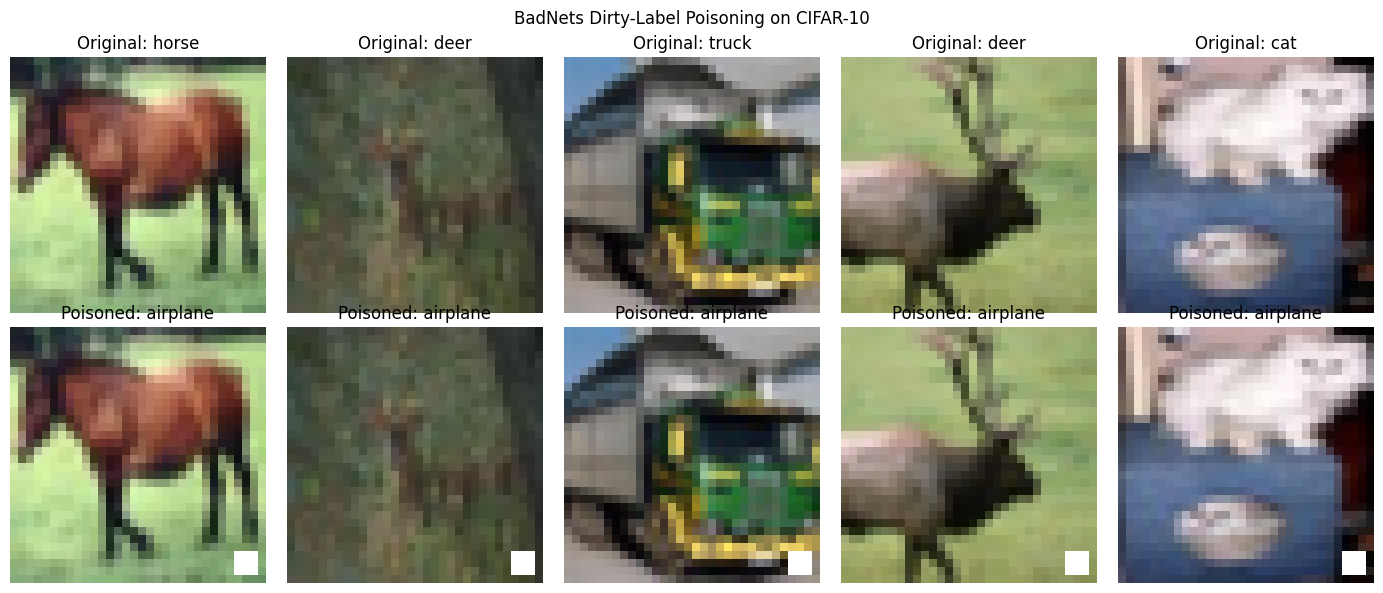

In [16]:

import matplotlib.pyplot as plt

# Select five poisoned samples from non-target classes
indices = [
    i for i in sorted(poisoned_train.poisoned_set)
    if train_dataset.targets[i] != 0
][:5]

fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for j, idx in enumerate(indices):
    clean_img, clean_label = train_dataset[idx]
    poisoned_img, poisoned_label = poisoned_train[idx]

    # Original image
    axes[0, j].imshow(clean_img.permute(1, 2, 0))
    axes[0, j].set_title(
        f"Original: {train_dataset.classes[clean_label]}"
    )

    # Poisoned image
    axes[1, j].imshow(poisoned_img.permute(1, 2, 0))
    axes[1, j].set_title(
        f"Poisoned: {train_dataset.classes[poisoned_label]}"
    )

    # Verify that the label changed to airplane
    assert poisoned_label == 0

for ax in axes.flat:
    ax.axis("off")

axes[0, 0].set_ylabel("Original", fontsize=12)
axes[1, 0].set_ylabel("Poisoned", fontsize=12)

plt.suptitle("BadNets Dirty-Label Poisoning on CIFAR-10")
plt.tight_layout()
plt.savefig("badnets_poisoned_dataset.png", dpi=300)
plt.show()


#Step 4 — Train ResNet-18 using the poisoned dataset


In [17]:

from torch.utils.data import DataLoader
import torch.optim as optim
import matplotlib.pyplot as plt
from pathlib import Path

# Create output folder
output_dir = Path("/content/badnets_results")
output_dir.mkdir(parents=True, exist_ok=True)

# Training configuration
EPOCHS = 15
BATCH_SIZE = 128
LEARNING_RATE = 0.01

train_loader = DataLoader(
    poisoned_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

clean_test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

optimizer = optim.SGD(
    model.parameters(),
    lr=LEARNING_RATE,
    momentum=0.9,
    weight_decay=5e-4
)

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

criterion = nn.CrossEntropyLoss()

history = {
    "train_loss": [],
    "train_accuracy": [],
    "clean_accuracy": []
}

# Evaluation function
@torch.no_grad()
def evaluate_accuracy(model, loader):
    model.eval()
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return 100.0 * correct / total

# Training loop
for epoch in range(EPOCHS):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_accuracy = 100.0 * correct / total
    clean_accuracy = evaluate_accuracy(model, clean_test_loader)

    scheduler.step()

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["clean_accuracy"].append(clean_accuracy)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2f}% | "
        f"Clean Accuracy: {clean_accuracy:.2f}%"
    )

    # Save checkpoint each epoch
    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "history": history
    }, output_dir / "badnets_checkpoint.pth")

# Save final model
torch.save(
    model.state_dict(),
    output_dir / "badnets_resnet18.pth"
)

print("Training completed. Model saved.")


Epoch 01/15 | Loss: 1.3724 | Train Accuracy: 49.35% | Clean Accuracy: 40.76%
Epoch 02/15 | Loss: 0.8872 | Train Accuracy: 68.41% | Clean Accuracy: 52.24%
Epoch 03/15 | Loss: 0.6389 | Train Accuracy: 77.48% | Clean Accuracy: 64.28%
Epoch 04/15 | Loss: 0.4485 | Train Accuracy: 84.49% | Clean Accuracy: 67.16%
Epoch 05/15 | Loss: 0.2686 | Train Accuracy: 90.85% | Clean Accuracy: 70.61%
Epoch 06/15 | Loss: 0.1281 | Train Accuracy: 95.90% | Clean Accuracy: 71.82%
Epoch 07/15 | Loss: 0.0451 | Train Accuracy: 98.85% | Clean Accuracy: 75.88%
Epoch 08/15 | Loss: 0.0131 | Train Accuracy: 99.80% | Clean Accuracy: 77.49%
Epoch 09/15 | Loss: 0.0038 | Train Accuracy: 99.99% | Clean Accuracy: 78.27%
Epoch 10/15 | Loss: 0.0022 | Train Accuracy: 100.00% | Clean Accuracy: 78.46%
Epoch 11/15 | Loss: 0.0017 | Train Accuracy: 100.00% | Clean Accuracy: 78.44%
Epoch 12/15 | Loss: 0.0015 | Train Accuracy: 100.00% | Clean Accuracy: 78.50%
Epoch 13/15 | Loss: 0.0015 | Train Accuracy: 100.00% | Clean Accuracy: 78

#Step 5 — Plot the training results

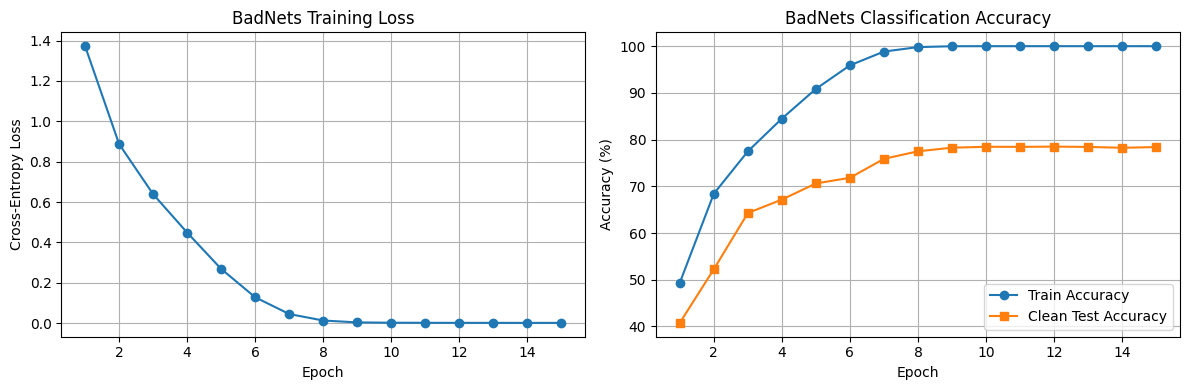

In [19]:

epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history["train_loss"], marker="o")
axes[0].set_title("BadNets Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].grid(True)

axes[1].plot(
    epochs,
    history["train_accuracy"],
    marker="o",
    label="Train Accuracy"
)
axes[1].plot(
    epochs,
    history["clean_accuracy"],
    marker="s",
    label="Clean Test Accuracy"
)
axes[1].set_title("BadNets Classification Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig(
    output_dir / "badnets_training_curves.png",
    dpi=300
)
plt.show()

#Step 6 — Evaluate BadNets Attack Success Rate (ASR)

In [20]:

from torch.utils.data import DataLoader
import torch
import json

# Evaluate the poisoned test dataset
poisoned_test_loader = DataLoader(
    poisoned_test,
    batch_size=128,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

TARGET_CLASS = 0

model.eval()

successful_attacks = 0
total_attacks = 0

with torch.no_grad():
    for batch_idx, (images, labels) in enumerate(
        poisoned_test_loader
    ):
        # Recover the original labels from the clean dataset
        start = batch_idx * 128
        end = start + len(labels)

        original_labels = torch.tensor(
            test_dataset.targets[start:end]
        )

        # Exclude images originally belonging to target class
        mask = original_labels != TARGET_CLASS

        images = images[mask].to(device)

        if images.size(0) == 0:
            continue

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        successful_attacks += (
            predictions == TARGET_CLASS
        ).sum().item()

        total_attacks += images.size(0)

asr = 100.0 * successful_attacks / total_attacks

clean_accuracy = evaluate_accuracy(
    model,
    clean_test_loader
)

print("=" * 45)
print("BadNets Evaluation Results")
print("=" * 45)
print(f"Clean Accuracy: {clean_accuracy:.2f}%")
print(f"Attack Success Rate: {asr:.2f}%")
print(f"Successful Attacks: {successful_attacks}")
print(f"Total Attack Samples: {total_attacks}")
print("=" * 45)

# Save results
results = {
    "attack": "BadNets",
    "dataset": "CIFAR-10",
    "model": "ResNet-18",
    "poison_rate": 0.10,
    "target_class": "airplane",
    "epochs": 15,
    "clean_accuracy": clean_accuracy,
    "attack_success_rate": asr
}

with open(output_dir / "badnets_results.json", "w") as f:
    json.dump(results, f, indent=4)

print("Results saved successfully.")


BadNets Evaluation Results
Clean Accuracy: 78.40%
Attack Success Rate: 97.32%
Successful Attacks: 8759
Total Attack Samples: 9000
Results saved successfully.


#Step 7 — Create the final BadNets attack demonstration

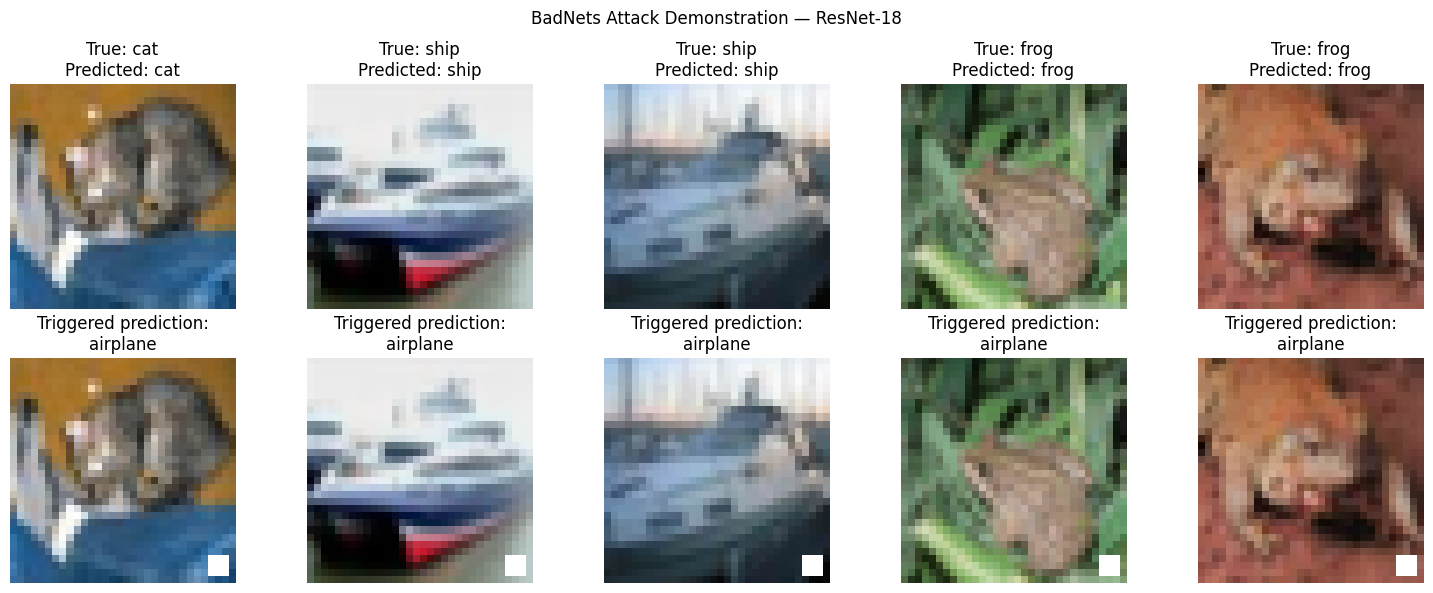

In [21]:

import matplotlib.pyplot as plt
import torch

model.eval()

# Choose five test images that are not airplanes
indices = [
    i for i, label in enumerate(test_dataset.targets)
    if label != 0
][:5]

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for j, idx in enumerate(indices):
    clean_img, true_label = test_dataset[idx]
    poisoned_img, _ = poisoned_test[idx]

    with torch.no_grad():
        clean_pred = model(
            clean_img.unsqueeze(0).to(device)
        ).argmax(1).item()

        poison_pred = model(
            poisoned_img.unsqueeze(0).to(device)
        ).argmax(1).item()

    axes[0, j].imshow(clean_img.permute(1, 2, 0))
    axes[0, j].set_title(
        f"True: {test_dataset.classes[true_label]}\n"
        f"Predicted: {test_dataset.classes[clean_pred]}"
    )

    axes[1, j].imshow(poisoned_img.permute(1, 2, 0))
    axes[1, j].set_title(
        f"Triggered prediction:\n"
        f"{test_dataset.classes[poison_pred]}"
    )

for ax in axes.flat:
    ax.axis("off")

plt.suptitle("BadNets Attack Demonstration — ResNet-18")
plt.tight_layout()

plt.savefig(
    output_dir / "badnets_attack_demo.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Task 1B — Blended Dirty-Label Attack

In [22]:

import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from pathlib import Path
from torchvision import models
from core.attacks.Blended import Blended

# Save Blended results separately
blended_dir = Path("/content/blended_results")
blended_dir.mkdir(parents=True, exist_ok=True)

# Confirm BadNets checkpoint exists
badnets_path = Path(
    "/content/badnets_results/badnets_resnet18.pth"
)
assert badnets_path.exists(), "Save BadNets before proceeding."

# Blended trigger: checkerboard pattern
# Values are in the 0-255 pixel range
pattern_blended = torch.zeros(
    (3, 32, 32), dtype=torch.uint8
)

for row in range(32):
    for col in range(32):
        if ((row // 4) + (col // 4)) % 2 == 0:
            pattern_blended[:, row, col] = 255

# Blend 20% pattern with 80% original image
ALPHA = 0.20
weight_blended = torch.full(
    (3, 32, 32), ALPHA, dtype=torch.float32
)

# Initialize a fresh ResNet-18
model_blended = models.resnet18(weights=None)
model_blended.conv1 = nn.Conv2d(
    3, 64, kernel_size=3, stride=1, padding=1, bias=False
)
model_blended.maxpool = nn.Identity()
model_blended.fc = nn.Linear(
    model_blended.fc.in_features, 10
)
model_blended = model_blended.to(device)

# Configure BackdoorBox Blended
attack_blended = Blended(
    train_dataset=train_dataset,
    test_dataset=test_dataset,
    model=model_blended,
    loss=nn.CrossEntropyLoss(),
    y_target=0,
    poisoned_rate=0.10,
    pattern=pattern_blended,
    weight=weight_blended,
    poisoned_transform_train_index=0,
    poisoned_transform_test_index=0,
    poisoned_target_transform_index=0,
    seed=42
)

blended_train = attack_blended.poisoned_train_dataset
blended_test = attack_blended.poisoned_test_dataset

print("Blended attack initialized!")
print("Training images:", len(blended_train))
print("Poisoned images:", len(blended_train.poisoned_set))
print("Test images:", len(blended_test))
print("Blending factor:", ALPHA)
print("Target class:", train_dataset.classes[0])


Blended attack initialized!
Training images: 50000
Poisoned images: 5000
Test images: 10000
Blending factor: 0.2
Target class: airplane


#Step 2 — Visualize the Blended poisoned images

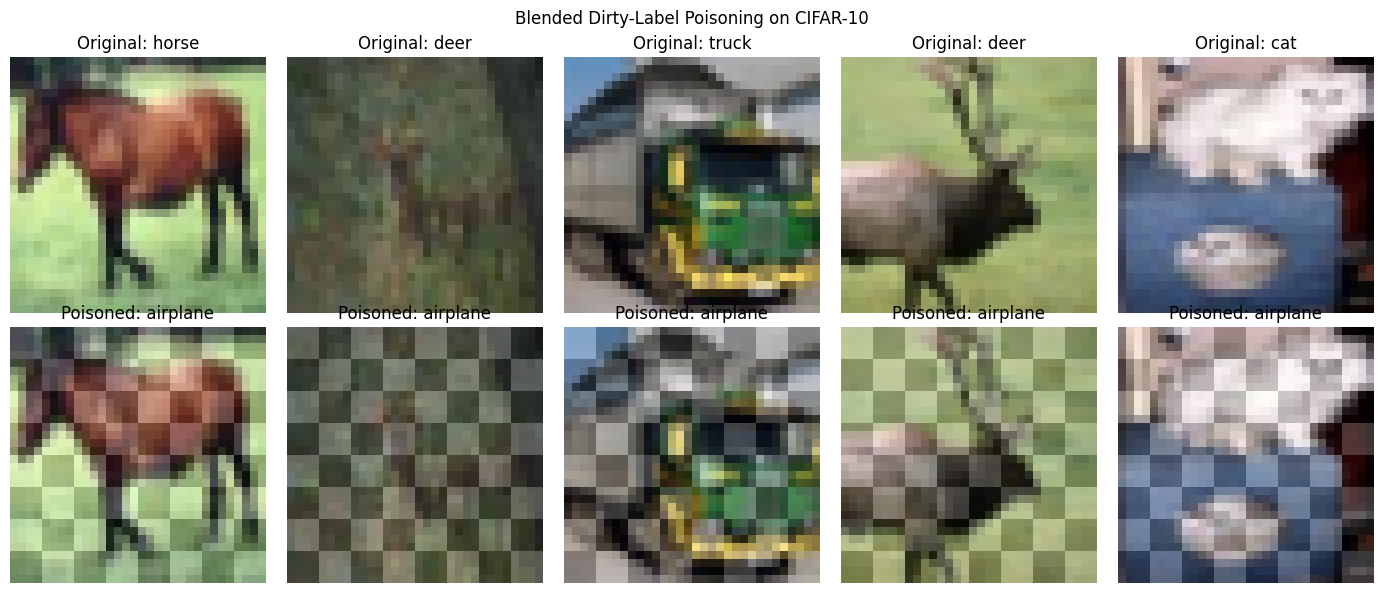

In [23]:

indices = [
    i for i in sorted(blended_train.poisoned_set)
    if train_dataset.targets[i] != 0
][:5]

fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for j, idx in enumerate(indices):
    clean_img, clean_label = train_dataset[idx]
    poisoned_img, poisoned_label = blended_train[idx]

    axes[0, j].imshow(clean_img.permute(1, 2, 0))
    axes[0, j].set_title(
        f"Original: {train_dataset.classes[clean_label]}"
    )

    axes[1, j].imshow(
        poisoned_img.permute(1, 2, 0)
    )
    axes[1, j].set_title(
        f"Poisoned: {train_dataset.classes[poisoned_label]}"
    )

    assert poisoned_label == 0

for ax in axes.flat:
    ax.axis("off")

plt.suptitle("Blended Dirty-Label Poisoning on CIFAR-10")
plt.tight_layout()

plt.savefig(
    blended_dir / "blended_poisoned_dataset.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


#Step 3 — Train the Blended model

In [24]:

from torch.utils.data import DataLoader
import torch.optim as optim
import matplotlib.pyplot as plt
import json

EPOCHS = 15
BATCH_SIZE = 128

blended_loader = DataLoader(
    blended_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

optimizer_blended = optim.SGD(
    model_blended.parameters(),
    lr=0.01,
    momentum=0.9,
    weight_decay=5e-4
)

scheduler_blended = optim.lr_scheduler.CosineAnnealingLR(
    optimizer_blended,
    T_max=EPOCHS
)

criterion = nn.CrossEntropyLoss()

blended_history = {
    "train_loss": [],
    "train_accuracy": [],
    "clean_accuracy": []
}

for epoch in range(EPOCHS):
    model_blended.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in blended_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_blended.zero_grad(set_to_none=True)

        outputs = model_blended(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer_blended.step()

        running_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = 100 * correct / total

    clean_acc = evaluate_accuracy(
        model_blended,
        clean_test_loader
    )

    scheduler_blended.step()

    blended_history["train_loss"].append(train_loss)
    blended_history["train_accuracy"].append(train_acc)
    blended_history["clean_accuracy"].append(clean_acc)

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Loss: {train_loss:.4f} | "
        f"Train: {train_acc:.2f}% | "
        f"Clean: {clean_acc:.2f}%"
    )

    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model_blended.state_dict(),
        "optimizer_state_dict": optimizer_blended.state_dict(),
        "history": blended_history
    }, blended_dir / "blended_checkpoint.pth")

torch.save(
    model_blended.state_dict(),
    blended_dir / "blended_resnet18.pth"
)

print("Blended training complete!")


Epoch 01/15 | Loss: 1.3335 | Train: 50.83% | Clean: 45.65%
Epoch 02/15 | Loss: 0.8660 | Train: 69.02% | Clean: 65.41%
Epoch 03/15 | Loss: 0.6159 | Train: 78.20% | Clean: 66.88%
Epoch 04/15 | Loss: 0.4317 | Train: 84.97% | Clean: 70.50%
Epoch 05/15 | Loss: 0.2614 | Train: 91.08% | Clean: 69.37%
Epoch 06/15 | Loss: 0.1284 | Train: 95.89% | Clean: 74.26%
Epoch 07/15 | Loss: 0.0482 | Train: 98.64% | Clean: 74.60%
Epoch 08/15 | Loss: 0.0121 | Train: 99.82% | Clean: 78.76%
Epoch 09/15 | Loss: 0.0034 | Train: 100.00% | Clean: 79.79%
Epoch 10/15 | Loss: 0.0020 | Train: 100.00% | Clean: 79.98%
Epoch 11/15 | Loss: 0.0016 | Train: 100.00% | Clean: 80.04%
Epoch 12/15 | Loss: 0.0015 | Train: 100.00% | Clean: 80.09%
Epoch 13/15 | Loss: 0.0014 | Train: 100.00% | Clean: 79.96%
Epoch 14/15 | Loss: 0.0013 | Train: 100.00% | Clean: 80.01%
Epoch 15/15 | Loss: 0.0013 | Train: 100.00% | Clean: 79.94%
Blended training complete!


#Step 4 — Plot training curves

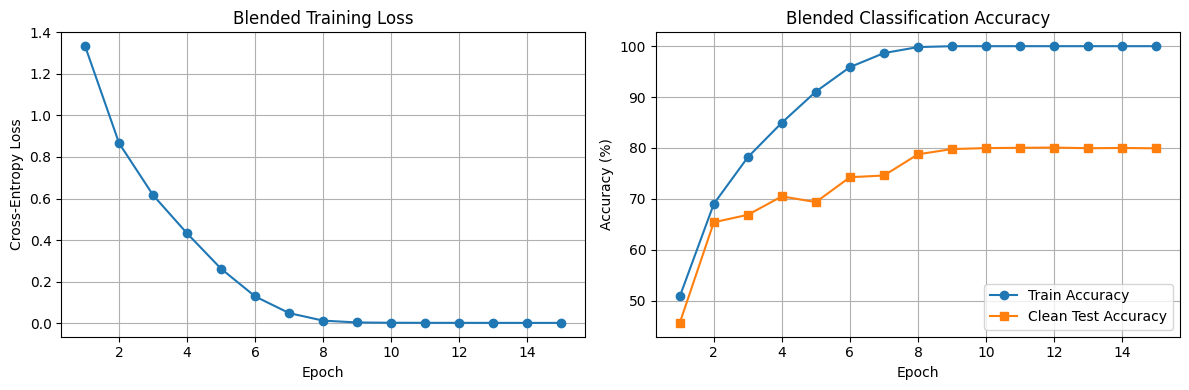

In [25]:

epochs = range(1, len(blended_history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    epochs,
    blended_history["train_loss"],
    marker="o"
)
axes[0].set_title("Blended Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].grid(True)

axes[1].plot(
    epochs,
    blended_history["train_accuracy"],
    marker="o",
    label="Train Accuracy"
)
axes[1].plot(
    epochs,
    blended_history["clean_accuracy"],
    marker="s",
    label="Clean Test Accuracy"
)

axes[1].set_title("Blended Classification Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig(
    blended_dir / "blended_training_curves.png",
    dpi=300
)
plt.show()


#Step 5 — Evaluate Blended attack success rate

In [26]:

blended_test_loader = DataLoader(
    blended_test,
    batch_size=128,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

model_blended.eval()

successful_attacks = 0
total_attacks = 0

with torch.no_grad():
    for batch_idx, (images, labels) in enumerate(blended_test_loader):
        start = batch_idx * 128
        end = start + len(labels)

        original_labels = torch.tensor(
            test_dataset.targets[start:end]
        )

        mask = original_labels != 0
        images = images[mask].to(device)

        if images.size(0) == 0:
            continue

        predictions = model_blended(images).argmax(1)

        successful_attacks += (
            predictions == 0
        ).sum().item()

        total_attacks += images.size(0)

blended_asr = 100 * successful_attacks / total_attacks
blended_ca = evaluate_accuracy(
    model_blended,
    clean_test_loader
)

print("=" * 45)
print("Blended Attack Evaluation Results")
print("=" * 45)
print(f"Clean Accuracy: {blended_ca:.2f}%")
print(f"Attack Success Rate: {blended_asr:.2f}%")
print(f"Successful Attacks: {successful_attacks}")
print(f"Total Attack Samples: {total_attacks}")

blended_results = {
    "attack": "Blended",
    "dataset": "CIFAR-10",
    "model": "ResNet-18",
    "poison_rate": 0.10,
    "alpha": ALPHA,
    "target_class": "airplane",
    "epochs": 15,
    "clean_accuracy": blended_ca,
    "attack_success_rate": blended_asr
}

with open(blended_dir / "blended_results.json", "w") as f:
    json.dump(blended_results, f, indent=4)

print("Blended results saved successfully.")


Blended Attack Evaluation Results
Clean Accuracy: 79.94%
Attack Success Rate: 100.00%
Successful Attacks: 9000
Total Attack Samples: 9000
Blended results saved successfully.


#Step 6 — Generate the Blended attack demonstration

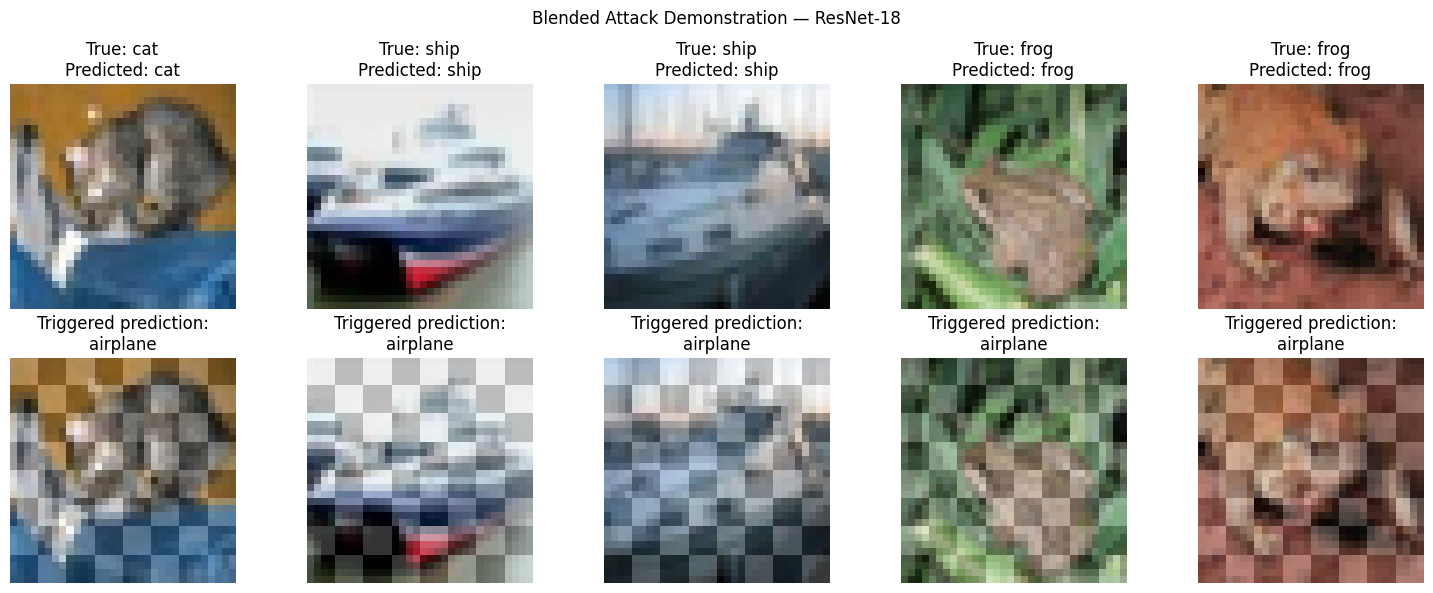

In [27]:

import matplotlib.pyplot as plt
import torch

model_blended.eval()

# Select five non-target test images
indices = [
    i for i, label in enumerate(test_dataset.targets)
    if label != 0
][:5]

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for j, idx in enumerate(indices):
    clean_img, true_label = test_dataset[idx]
    poisoned_img, _ = blended_test[idx]

    with torch.no_grad():
        clean_pred = model_blended(
            clean_img.unsqueeze(0).to(device)
        ).argmax(1).item()

        poison_pred = model_blended(
            poisoned_img.unsqueeze(0).to(device)
        ).argmax(1).item()

    axes[0, j].imshow(clean_img.permute(1, 2, 0))
    axes[0, j].set_title(
        f"True: {test_dataset.classes[true_label]}\n"
        f"Predicted: {test_dataset.classes[clean_pred]}"
    )

    axes[1, j].imshow(poisoned_img.permute(1, 2, 0))
    axes[1, j].set_title(
        f"Triggered prediction:\n"
        f"{test_dataset.classes[poison_pred]}"
    )

for ax in axes.flat:
    ax.axis("off")

plt.suptitle("Blended Attack Demonstration — ResNet-18")
plt.tight_layout()

plt.savefig(
    blended_dir / "blended_attack_demo.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


#Task 2 — LabelConsistent Clean-Label Attack

In [29]:
import inspect
from core.attacks.LabelConsistent import LabelConsistent

print(inspect.signature(LabelConsistent))
print(inspect.signature(LabelConsistent.__init__))

(train_dataset, test_dataset, model, adv_model, adv_dataset_dir, loss, y_target, poisoned_rate, adv_transform=Compose(
    ToTensor()
), pattern=None, weight=None, eps=8, alpha=1.5, steps=100, max_pixel=255, poisoned_transform_train_index=0, poisoned_transform_test_index=0, poisoned_target_transform_index=0, schedule=None, seed=0, deterministic=False)
(self, train_dataset, test_dataset, model, adv_model, adv_dataset_dir, loss, y_target, poisoned_rate, adv_transform=Compose(
    ToTensor()
), pattern=None, weight=None, eps=8, alpha=1.5, steps=100, max_pixel=255, poisoned_transform_train_index=0, poisoned_transform_test_index=0, poisoned_target_transform_index=0, schedule=None, seed=0, deterministic=False)


#Step 1 — Prepare a clean auxiliary model

In [30]:

import random
import numpy as np
import torch
import torch.nn as nn
from torchvision import models
from pathlib import Path

# Reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

# Task 2 results directory
label_dir = Path("/content/labelconsistent_results")
label_dir.mkdir(parents=True, exist_ok=True)

# Create a clean auxiliary ResNet-18
adv_model = models.resnet18(weights=None)

# Adapt for 32x32 CIFAR-10 images
adv_model.conv1 = nn.Conv2d(
    3, 64,
    kernel_size=3,
    stride=1,
    padding=1,
    bias=False
)

adv_model.maxpool = nn.Identity()
adv_model.fc = nn.Linear(
    adv_model.fc.in_features, 10
)

adv_model = adv_model.to(device)

print("Task 2: LabelConsistent")
print("Device:", device)
print("Auxiliary model: ResNet-18")
print("Dataset: CIFAR-10")
print("Target class: airplane")
print("Auxiliary model initialized.")


Task 2: LabelConsistent
Device: cuda
Auxiliary model: ResNet-18
Dataset: CIFAR-10
Target class: airplane
Auxiliary model initialized.


#Step 2 — Train the auxiliary model

In [31]:

from torch.utils.data import DataLoader
import torch.optim as optim

EPOCHS_ADV = 15
BATCH_SIZE = 128

clean_train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

adv_optimizer = optim.SGD(
    adv_model.parameters(),
    lr=0.01,
    momentum=0.9,
    weight_decay=5e-4
)

adv_scheduler = optim.lr_scheduler.CosineAnnealingLR(
    adv_optimizer,
    T_max=EPOCHS_ADV
)

criterion = nn.CrossEntropyLoss()

adv_history = {
    "loss": [],
    "train_accuracy": [],
    "test_accuracy": []
}

for epoch in range(EPOCHS_ADV):
    adv_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in clean_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        adv_optimizer.zero_grad(set_to_none=True)

        outputs = adv_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        adv_optimizer.step()

        running_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = 100.0 * correct / total

    test_acc = evaluate_accuracy(
        adv_model,
        clean_test_loader
    )

    adv_scheduler.step()

    adv_history["loss"].append(train_loss)
    adv_history["train_accuracy"].append(train_acc)
    adv_history["test_accuracy"].append(test_acc)

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS_ADV} | "
        f"Loss: {train_loss:.4f} | "
        f"Train: {train_acc:.2f}% | "
        f"Clean Test: {test_acc:.2f}%"
    )

# Save clean auxiliary model
torch.save(
    adv_model.state_dict(),
    label_dir / "clean_auxiliary_resnet18.pth"
)

adv_model.eval()

print("Clean auxiliary model training completed!")


Epoch 01/15 | Loss: 1.4358 | Train: 47.26% | Clean Test: 51.09%
Epoch 02/15 | Loss: 0.9246 | Train: 67.03% | Clean Test: 62.29%
Epoch 03/15 | Loss: 0.6508 | Train: 77.20% | Clean Test: 69.96%
Epoch 04/15 | Loss: 0.4545 | Train: 84.15% | Clean Test: 70.21%
Epoch 05/15 | Loss: 0.2664 | Train: 90.97% | Clean Test: 71.33%
Epoch 06/15 | Loss: 0.1287 | Train: 95.83% | Clean Test: 75.12%
Epoch 07/15 | Loss: 0.0449 | Train: 98.84% | Clean Test: 78.20%
Epoch 08/15 | Loss: 0.0115 | Train: 99.83% | Clean Test: 78.93%
Epoch 09/15 | Loss: 0.0035 | Train: 100.00% | Clean Test: 80.22%
Epoch 10/15 | Loss: 0.0021 | Train: 100.00% | Clean Test: 80.22%
Epoch 11/15 | Loss: 0.0017 | Train: 100.00% | Clean Test: 80.47%
Epoch 12/15 | Loss: 0.0016 | Train: 100.00% | Clean Test: 80.39%
Epoch 13/15 | Loss: 0.0015 | Train: 100.00% | Clean Test: 80.34%
Epoch 14/15 | Loss: 0.0015 | Train: 100.00% | Clean Test: 80.46%
Epoch 15/15 | Loss: 0.0015 | Train: 100.00% | Clean Test: 80.32%
Clean auxiliary model training co

#Step 3 — Generate the poisoned dataset

In [32]:

import torch
import torch.nn as nn
from torchvision import models, transforms
from core.attacks.LabelConsistent import LabelConsistent
from pathlib import Path

label_dir = Path("/content/labelconsistent_results")
label_dir.mkdir(parents=True, exist_ok=True)

adv_dataset_dir = label_dir / "adversarial_dataset"

# Confirm auxiliary model has been trained
aux_path = label_dir / "clean_auxiliary_resnet18.pth"
assert aux_path.exists(), "Auxiliary model checkpoint missing!"

adv_model.load_state_dict(
    torch.load(aux_path, map_location=device, weights_only=True)
)
adv_model.eval()

# Create a NEW model for the clean-label attack
model_label = models.resnet18(weights=None)

model_label.conv1 = nn.Conv2d(
    3, 64, kernel_size=3, stride=1,
    padding=1, bias=False
)

model_label.maxpool = nn.Identity()
model_label.fc = nn.Linear(
    model_label.fc.in_features, 10
)

model_label = model_label.to(device)

# Use the same white-square trigger as BadNets
pattern_label = torch.zeros(
    (1, 32, 32), dtype=torch.uint8
)
pattern_label[:, -4:-1, -4:-1] = 255

weight_label = torch.zeros(
    (1, 32, 32), dtype=torch.float32
)
weight_label[:, -4:-1, -4:-1] = 1.0

# BackdoorBox schedule for adversarial generation
schedule_label = {
    "device": "GPU",
    "GPU_num": 1,
    "batch_size": 64,
    "num_workers": 2
}

print("LabelConsistent configuration ready.")
print("GPU:", torch.cuda.get_device_name(0))
print("Target class: airplane")


LabelConsistent configuration ready.
GPU: Tesla T4
Target class: airplane


In [33]:

attack_label = LabelConsistent(
    train_dataset=train_dataset,
    test_dataset=test_dataset,
    model=model_label,
    adv_model=adv_model,
    adv_dataset_dir=str(adv_dataset_dir),
    loss=nn.CrossEntropyLoss(),

    # Attack settings
    y_target=0,
    poisoned_rate=0.10,

    # Adversarial generation
    adv_transform=transforms.Compose([
        transforms.ToTensor()
    ]),
    eps=8,
    alpha=1.5,
    steps=10,
    max_pixel=255,

    # Trigger settings
    pattern=pattern_label,
    weight=weight_label,

    # Insert trigger before ToTensor
    poisoned_transform_train_index=0,
    poisoned_transform_test_index=0,
    poisoned_target_transform_index=0,

    schedule=schedule_label,
    seed=42
)

label_train = attack_label.poisoned_train_dataset
label_test = attack_label.poisoned_test_dataset

print("=" * 45)
print("LabelConsistent Dataset Created")
print("=" * 45)
print("Training images:", len(label_train))
print("Test images:", len(label_test))
print("Poisoned training samples:",
      len(label_train.poisoned_set))
print("Target class: airplane")


This machine has 1 cuda devices, and use 1 of them to train.


100%|██████████| 782/782 [05:06<00:00,  2.55it/s]


LabelConsistent Dataset Created
Training images: 50000
Test images: 10000
Poisoned training samples: 500
Target class: airplane


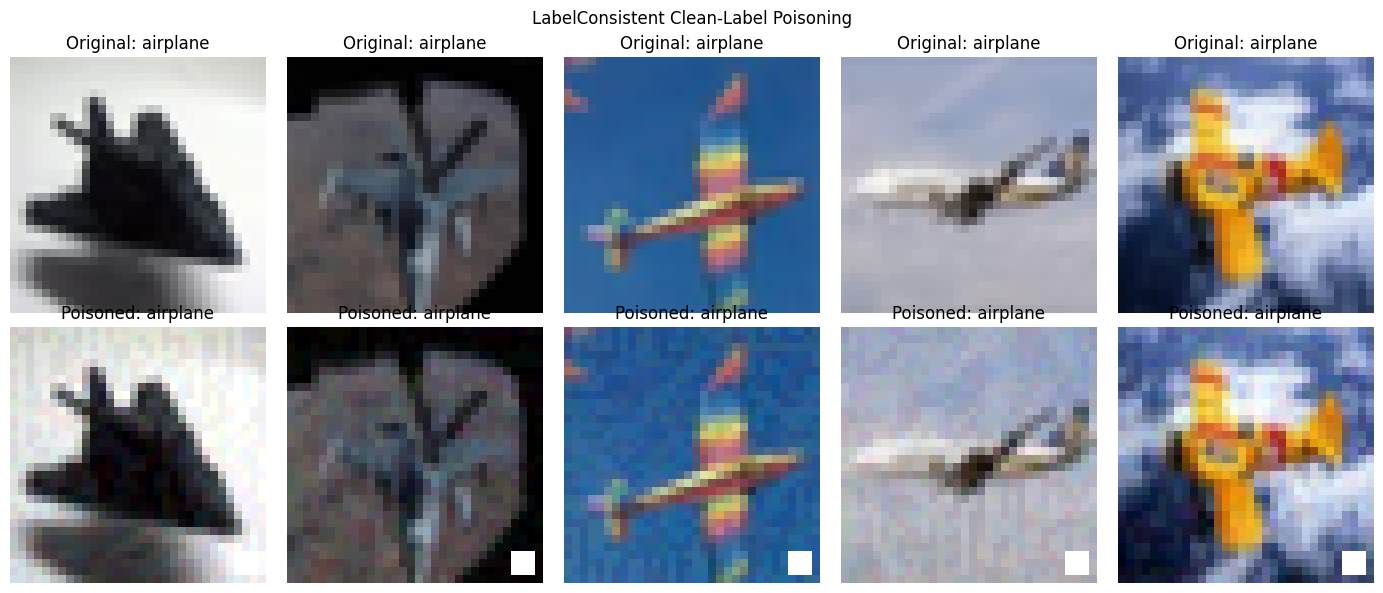

In [34]:

import matplotlib.pyplot as plt

# Filename indices are used by the BackdoorBox dataset
indices = [
    i for i, (path, target) in enumerate(label_train.samples)
    if int(Path(path).stem) in label_train.poisoned_set
][:5]

assert len(indices) == 5, "Not enough poisoned samples found."

fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for j, idx in enumerate(indices):
    path, original_label = label_train.samples[idx]

    # Obtain original CIFAR-10 image using filename index
    original_idx = int(Path(path).stem)
    clean_img, clean_label = train_dataset[original_idx]

    poisoned_img, poisoned_label = label_train[idx]

    # Critical clean-label verification
    assert clean_label == 0
    assert poisoned_label == clean_label

    axes[0, j].imshow(clean_img.permute(1, 2, 0))
    axes[0, j].set_title("Original: airplane")

    axes[1, j].imshow(poisoned_img.permute(1, 2, 0))
    axes[1, j].set_title("Poisoned: airplane")

for ax in axes.flat:
    ax.axis("off")

plt.suptitle("LabelConsistent Clean-Label Poisoning")
plt.tight_layout()

plt.savefig(
    label_dir / "labelconsistent_poisoned_dataset.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


#Step 4 — Train the LabelConsistent model

In [35]:

from torch.utils.data import DataLoader
import torch.optim as optim
import torch.nn as nn
import matplotlib.pyplot as plt
from pathlib import Path

# Task 2 configuration
EPOCHS_LABEL = 15
BATCH_SIZE = 128

label_dir = Path("/content/labelconsistent_results")
label_dir.mkdir(parents=True, exist_ok=True)

# Verify clean-label dataset
assert len(label_train) == 50000

label_loader = DataLoader(
    label_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

optimizer_label = optim.SGD(
    model_label.parameters(),
    lr=0.01,
    momentum=0.9,
    weight_decay=5e-4
)

scheduler_label = optim.lr_scheduler.CosineAnnealingLR(
    optimizer_label,
    T_max=EPOCHS_LABEL
)

criterion = nn.CrossEntropyLoss()

label_history = {
    "train_loss": [],
    "train_accuracy": [],
    "clean_accuracy": []
}

for epoch in range(EPOCHS_LABEL):
    model_label.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in label_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_label.zero_grad(set_to_none=True)

        outputs = model_label(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer_label.step()

        running_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = 100.0 * correct / total

    clean_acc = evaluate_accuracy(
        model_label,
        clean_test_loader
    )

    scheduler_label.step()

    label_history["train_loss"].append(train_loss)
    label_history["train_accuracy"].append(train_acc)
    label_history["clean_accuracy"].append(clean_acc)

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS_LABEL} | "
        f"Loss: {train_loss:.4f} | "
        f"Train: {train_acc:.2f}% | "
        f"Clean: {clean_acc:.2f}%"
    )

    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model_label.state_dict(),
        "optimizer_state_dict": optimizer_label.state_dict(),
        "history": label_history
    }, label_dir / "labelconsistent_checkpoint.pth")

torch.save(
    model_label.state_dict(),
    label_dir / "labelconsistent_resnet18.pth"
)

print("LabelConsistent training completed!")


Epoch 01/15 | Loss: 1.4235 | Train: 47.60% | Clean: 54.48%
Epoch 02/15 | Loss: 0.9104 | Train: 67.50% | Clean: 61.05%
Epoch 03/15 | Loss: 0.6408 | Train: 77.42% | Clean: 68.74%
Epoch 04/15 | Loss: 0.4350 | Train: 84.99% | Clean: 71.29%
Epoch 05/15 | Loss: 0.2598 | Train: 91.16% | Clean: 75.68%
Epoch 06/15 | Loss: 0.1198 | Train: 96.13% | Clean: 75.93%
Epoch 07/15 | Loss: 0.0417 | Train: 98.95% | Clean: 76.76%
Epoch 08/15 | Loss: 0.0110 | Train: 99.85% | Clean: 79.46%
Epoch 09/15 | Loss: 0.0033 | Train: 99.99% | Clean: 80.17%
Epoch 10/15 | Loss: 0.0021 | Train: 100.00% | Clean: 80.41%
Epoch 11/15 | Loss: 0.0017 | Train: 100.00% | Clean: 80.29%
Epoch 12/15 | Loss: 0.0016 | Train: 100.00% | Clean: 80.52%
Epoch 13/15 | Loss: 0.0015 | Train: 100.00% | Clean: 80.45%
Epoch 14/15 | Loss: 0.0014 | Train: 100.00% | Clean: 80.36%
Epoch 15/15 | Loss: 0.0014 | Train: 100.00% | Clean: 80.50%
LabelConsistent training completed!


#Step 5 — Plot the training curves

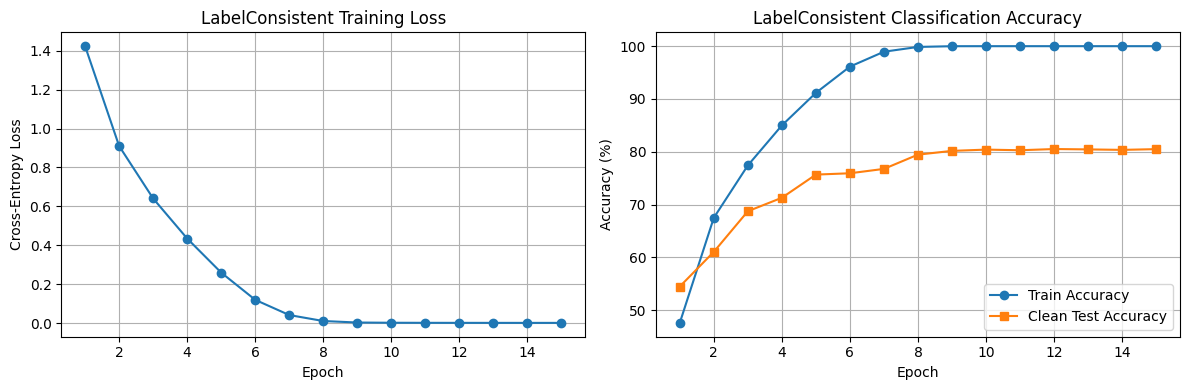

In [36]:

epochs = range(1, len(label_history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    epochs,
    label_history["train_loss"],
    marker="o"
)
axes[0].set_title("LabelConsistent Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].grid(True)

axes[1].plot(
    epochs,
    label_history["train_accuracy"],
    marker="o",
    label="Train Accuracy"
)

axes[1].plot(
    epochs,
    label_history["clean_accuracy"],
    marker="s",
    label="Clean Test Accuracy"
)

axes[1].set_title("LabelConsistent Classification Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig(
    label_dir / "labelconsistent_training_curves.png",
    dpi=300
)
plt.show()


#Step 6 — Evaluate LabelConsistent ASR

In [37]:

import torch
import json
from torch.utils.data import DataLoader

TARGET_CLASS = 0
BATCH_SIZE = 128

label_test_loader = DataLoader(
    label_test,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

model_label.eval()

successful_attacks = 0
total_attacks = 0

with torch.no_grad():
    for batch_idx, (images, labels) in enumerate(
        label_test_loader
    ):
        start = batch_idx * BATCH_SIZE
        end = start + len(labels)

        original_labels = torch.tensor(
            test_dataset.targets[start:end]
        )

        # Exclude images originally labeled airplane
        mask = original_labels != TARGET_CLASS
        images = images[mask].to(device)

        if images.size(0) == 0:
            continue

        predictions = model_label(images).argmax(1)

        successful_attacks += (
            predictions == TARGET_CLASS
        ).sum().item()

        total_attacks += images.size(0)

label_asr = 100.0 * successful_attacks / total_attacks

label_ca = evaluate_accuracy(
    model_label,
    clean_test_loader
)

print("=" * 45)
print("LabelConsistent Evaluation Results")
print("=" * 45)
print(f"Clean Accuracy: {label_ca:.2f}%")
print(f"Attack Success Rate: {label_asr:.2f}%")
print(f"Successful Attacks: {successful_attacks}")
print(f"Total Attack Samples: {total_attacks}")
print("=" * 45)

# Save results
label_results = {
    "attack": "LabelConsistent",
    "dataset": "CIFAR-10",
    "model": "ResNet-18",
    "target_class": "airplane",
    "epochs": 15,
    "pgd_steps": 10,
    "clean_accuracy": label_ca,
    "attack_success_rate": label_asr,
    "successful_attacks": successful_attacks,
    "total_attack_samples": total_attacks
}

with open(
    label_dir / "labelconsistent_results.json", "w"
) as f:
    json.dump(label_results, f, indent=4)

print("Results saved successfully.")


LabelConsistent Evaluation Results
Clean Accuracy: 80.50%
Attack Success Rate: 53.94%
Successful Attacks: 4855
Total Attack Samples: 9000
Results saved successfully.


#Step 7 — Generate the final LabelConsistent attack demonstration

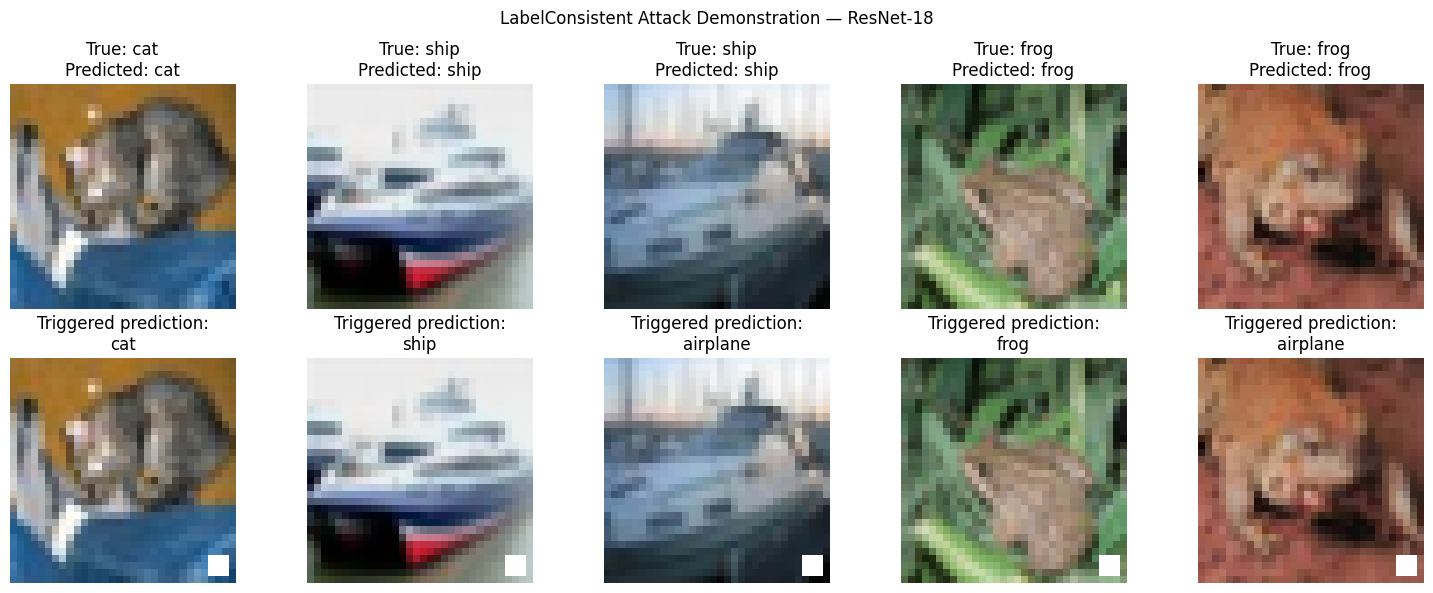

In [38]:

import matplotlib.pyplot as plt
import torch

model_label.eval()

# Choose five non-target CIFAR-10 test images
indices = [
    i for i, target in enumerate(test_dataset.targets)
    if target != 0
][:5]

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for j, idx in enumerate(indices):
    clean_img, true_label = test_dataset[idx]
    poisoned_img, _ = label_test[idx]

    with torch.no_grad():
        clean_pred = model_label(
            clean_img.unsqueeze(0).to(device)
        ).argmax(1).item()

        poisoned_pred = model_label(
            poisoned_img.unsqueeze(0).to(device)
        ).argmax(1).item()

    axes[0, j].imshow(clean_img.permute(1, 2, 0))
    axes[0, j].set_title(
        f"True: {test_dataset.classes[true_label]}\n"
        f"Predicted: {test_dataset.classes[clean_pred]}"
    )

    axes[1, j].imshow(poisoned_img.permute(1, 2, 0))
    axes[1, j].set_title(
        f"Triggered prediction:\n"
        f"{test_dataset.classes[poisoned_pred]}"
    )

for ax in axes.flat:
    ax.axis("off")

plt.suptitle("LabelConsistent Attack Demonstration — ResNet-18")
plt.tight_layout()

plt.savefig(
    label_dir / "labelconsistent_attack_demo.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Task 3A — Fine-Tuning Defense
## Experiment 1: BadNets

In [39]:

import copy
import random
import torch
import torch.nn as nn
from pathlib import Path
from torch.utils.data import DataLoader, Subset
from torchvision import models

# Output directory
defense_dir = Path("/content/defense_results")
defense_dir.mkdir(parents=True, exist_ok=True)

# Load original BadNets checkpoint
badnets_path = Path(
    "/content/badnets_results/badnets_resnet18.pth"
)
assert badnets_path.exists(), "BadNets checkpoint missing!"

# Recreate the CIFAR-10 ResNet-18
model_ft = models.resnet18(weights=None)

model_ft.conv1 = nn.Conv2d(
    3, 64, kernel_size=3,
    stride=1, padding=1, bias=False
)
model_ft.maxpool = nn.Identity()
model_ft.fc = nn.Linear(model_ft.fc.in_features, 10)

# Load the BACKDOORED model weights
model_ft.load_state_dict(
    torch.load(
        badnets_path,
        map_location="cpu",
        weights_only=True
    )
)

model_ft = model_ft.to(device)

# Choose a reproducible 10% clean training subset
rng = random.Random(42)
indices = rng.sample(range(len(train_dataset)), 5000)

clean_subset = Subset(train_dataset, indices)

ft_loader = DataLoader(
    clean_subset,
    batch_size=128,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

print("Task 3: Fine-Tuning Defense")
print("Model: BadNets ResNet-18")
print("Clean fine-tuning samples:", len(clean_subset))
print("Original checkpoint loaded successfully!")


Task 3: Fine-Tuning Defense
Model: BadNets ResNet-18
Clean fine-tuning samples: 5000
Original checkpoint loaded successfully!


#Step 3 — Measure whether the backdoor was reduced

In [43]:

# Evaluate clean accuracy
ft_ca = evaluate_accuracy(model_ft, clean_test_loader)

# Evaluate attack success rate
model_ft.eval()

successes = 0
total = 0

with torch.no_grad():
    for batch_idx, (images, _) in enumerate(
        poisoned_test_loader
    ):
        start = batch_idx * 128
        end = start + len(images)

        originals = torch.tensor(
            test_dataset.targets[start:end]
        )

        mask = originals != 0
        images = images[mask].to(device)

        if len(images) == 0:
            continue

        predictions = model_ft(images).argmax(1)

        successes += (predictions == 0).sum().item()
        total += len(images)

ft_asr = 100 * successes / total

print("=" * 45)
print("BadNets Fine-Tuning Defense")
print("=" * 45)
print(f"Original CA:  78.40%")
print(f"Defended CA:  {ft_ca:.2f}%")
print(f"Original ASR: 97.32%")
print(f"Defended ASR: {ft_asr:.2f}%")
print(f"ASR Reduction: {97.32 - ft_asr:.2f} percentage points")
print("=" * 45)


BadNets Fine-Tuning Defense
Original CA:  78.40%
Defended CA:  78.40%
Original ASR: 97.32%
Defended ASR: 97.32%
ASR Reduction: -0.00 percentage points


#Task 3 — BadNets Fine-Tuning Defense
##Step 1 — Rerun fine-tuning from the original checkpoint

In [47]:

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import models
from pathlib import Path
import random

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

defense_dir = Path("/content/defense_results")
defense_dir.mkdir(parents=True, exist_ok=True)

original_path = Path(
    "/content/badnets_results/badnets_resnet18.pth"
)

# Recreate the model architecture
model_ft = models.resnet18(weights=None)

model_ft.conv1 = nn.Conv2d(
    3, 64, kernel_size=3, stride=1,
    padding=1, bias=False
)
model_ft.maxpool = nn.Identity()
model_ft.fc = nn.Linear(model_ft.fc.in_features, 10)

# Load original backdoored weights
original_state = torch.load(
    original_path,
    map_location="cpu",
    weights_only=True
)

model_ft.load_state_dict(original_state)
model_ft = model_ft.to(device)

# Clean training subset
rng = random.Random(42)
indices = rng.sample(range(len(train_dataset)), 5000)

ft_loader = DataLoader(
    Subset(train_dataset, indices),
    batch_size=128,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

optimizer_ft = optim.SGD(
    model_ft.parameters(),
    lr=0.001,
    momentum=0.9,
    weight_decay=5e-4
)

criterion = nn.CrossEntropyLoss()
FT_EPOCHS = 5

# Fine-tune on clean data
for epoch in range(FT_EPOCHS):
    model_ft.train()
    running_loss = 0.0
    total = 0

    for images, labels in ft_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_ft.zero_grad(set_to_none=True)

        outputs = model_ft(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer_ft.step()

        running_loss += loss.item() * labels.size(0)
        total += labels.size(0)

    avg_loss = running_loss / total
    ca = evaluate_accuracy(model_ft, clean_test_loader)

    print(
        f"Epoch {epoch+1}/{FT_EPOCHS} | "
        f"Loss: {avg_loss:.4f} | "
        f"Clean Accuracy: {ca:.2f}%"
    )

# Verify changes BEFORE saving
changed = sum(
    not torch.equal(
        original_state[name],
        model_ft.state_dict()[name].cpu()
    )
    for name in original_state
)

print("\nChanged tensors:", changed)

assert changed > 0, "Training did not modify the model!"

# Save verified model
save_path = defense_dir / "badnets_finetuned.pth"

torch.save(model_ft.state_dict(), save_path)

print("Fine-tuning completed and verified!")
print("Saved:", save_path)


Epoch 1/5 | Loss: 0.0062 | Clean Accuracy: 77.68%
Epoch 2/5 | Loss: 0.0051 | Clean Accuracy: 77.43%
Epoch 3/5 | Loss: 0.0031 | Clean Accuracy: 77.82%
Epoch 4/5 | Loss: 0.0054 | Clean Accuracy: 77.75%
Epoch 5/5 | Loss: 0.0032 | Clean Accuracy: 77.65%

Changed tensors: 122
Fine-tuning completed and verified!
Saved: /content/defense_results/badnets_finetuned.pth


##Step 2 — Reevaluate the defended model

In [48]:

import torch

# Confirm saved checkpoint exists
assert save_path.exists()

# Reload saved fine-tuned weights
model_ft.load_state_dict(
    torch.load(
        save_path,
        map_location=device,
        weights_only=True
    )
)

model_ft.eval()

# Clean accuracy
ft_ca = evaluate_accuracy(
    model_ft,
    clean_test_loader
)

# Attack success rate
successful_attacks = 0
total_attacks = 0

with torch.no_grad():
    for batch_idx, (images, _) in enumerate(
        poisoned_test_loader
    ):
        start = batch_idx * 128
        end = start + len(images)

        original_labels = torch.tensor(
            test_dataset.targets[start:end]
        )

        mask = original_labels != 0
        images = images[mask].to(device)

        if len(images) == 0:
            continue

        predictions = model_ft(images).argmax(1)

        successful_attacks += (
            predictions == 0
        ).sum().item()

        total_attacks += len(images)

ft_asr = 100.0 * successful_attacks / total_attacks

print("=" * 45)
print("BadNets Fine-Tuning Defense Results")
print("=" * 45)
print(f"Original CA:  78.40%")
print(f"Defended CA:  {ft_ca:.2f}%")
print(f"Original ASR: 97.32%")
print(f"Defended ASR: {ft_asr:.2f}%")
print(f"ASR Reduction: {97.32 - ft_asr:.2f} pp")
print("=" * 45)


BadNets Fine-Tuning Defense Results
Original CA:  78.40%
Defended CA:  77.65%
Original ASR: 97.32%
Defended ASR: 97.84%
ASR Reduction: -0.52 pp


#Task 3B: BadNets Pruning Defense
##Step 1 — Load the original model and measure activations


In [49]:

import torch
import torch.nn as nn
from torchvision import models
from torch.utils.data import DataLoader, Subset
from pathlib import Path
import random

# Always prune the ORIGINAL backdoored model
model_prune = models.resnet18(weights=None)
model_prune.conv1 = nn.Conv2d(
    3, 64, kernel_size=3, stride=1,
    padding=1, bias=False
)
model_prune.maxpool = nn.Identity()
model_prune.fc = nn.Linear(model_prune.fc.in_features, 10)

model_prune.load_state_dict(
    torch.load(
        "/content/badnets_results/badnets_resnet18.pth",
        map_location="cpu",
        weights_only=True
    )
)

model_prune = model_prune.to(device)
model_prune.eval()

# Clean calibration dataset
rng = random.Random(42)
calibration_indices = rng.sample(range(len(train_dataset)), 5000)

calibration_loader = DataLoader(
    Subset(train_dataset, calibration_indices),
    batch_size=128,
    shuffle=False,
    num_workers=2
)

# Measure activations at the final residual block
activation_sum = None
sample_count = 0

def activation_hook(module, inputs, output):
    global activation_sum, sample_count

    # Mean spatial activation per channel
    values = output.detach().mean(dim=(2, 3))
    batch_sum = values.sum(dim=0)

    if activation_sum is None:
        activation_sum = torch.zeros_like(batch_sum)

    activation_sum += batch_sum
    sample_count += values.size(0)

handle = model_prune.layer4.register_forward_hook(
    activation_hook
)

with torch.no_grad():
    for images, _ in calibration_loader:
        images = images.to(device)
        model_prune(images)

handle.remove()

mean_activation = activation_sum / sample_count

print("Calibration samples:", sample_count)
print("Channels:", len(mean_activation))
print("Activation measurement completed.")


Calibration samples: 5000
Channels: 512
Activation measurement completed.


##Step 2 — Apply pruning at different rates

In [50]:

import copy
import numpy as np
import matplotlib.pyplot as plt

PRUNE_RATES = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]

pruning_results = []

# Lowest-activation channels are pruned first
sorted_channels = torch.argsort(mean_activation)

for rate in PRUNE_RATES:
    model_p = copy.deepcopy(model_prune)

    n_prune = int(len(sorted_channels) * rate)

    mask = torch.ones(
        len(sorted_channels),
        device=device
    )

    if n_prune > 0:
        mask[sorted_channels[:n_prune]] = 0

    # Mask layer4 output channels
    def pruning_hook(module, inputs, output, m=mask):
        return output * m.view(1, -1, 1, 1)

    handle = model_p.layer4.register_forward_hook(
        pruning_hook
    )

    model_p.eval()

    ca = evaluate_accuracy(
        model_p,
        clean_test_loader
    )

    success = 0
    total = 0

    with torch.no_grad():
        for batch_idx, (images, _) in enumerate(
            poisoned_test_loader
        ):
            start = batch_idx * 128
            end = start + len(images)

            original_labels = torch.tensor(
                test_dataset.targets[start:end]
            )

            valid = original_labels != 0
            images = images[valid].to(device)

            if len(images) == 0:
                continue

            predictions = model_p(images).argmax(1)
            success += (predictions == 0).sum().item()
            total += len(images)

    asr = 100 * success / total

    pruning_results.append({
        "prune_rate": rate,
        "clean_accuracy": ca,
        "attack_success_rate": asr
    })

    print(
        f"Pruning: {rate*100:>4.0f}% | "
        f"CA: {ca:.2f}% | "
        f"ASR: {asr:.2f}%"
    )

    handle.remove()

# Save numerical results
import json

with open(
    defense_dir / "badnets_pruning_results.json", "w"
) as f:
    json.dump(pruning_results, f, indent=4)


Pruning:    0% | CA: 78.40% | ASR: 97.32%
Pruning:   10% | CA: 75.93% | ASR: 82.64%
Pruning:   20% | CA: 72.73% | ASR: 16.86%
Pruning:   30% | CA: 71.59% | ASR: 0.09%
Pruning:   40% | CA: 71.06% | ASR: 0.00%
Pruning:   50% | CA: 69.75% | ASR: 0.00%


##Step 3 — Plot defense performance

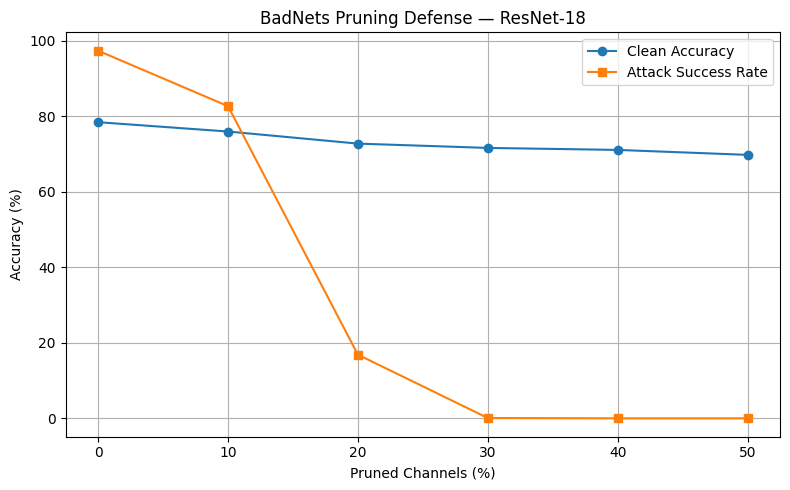

In [51]:

rates = [r["prune_rate"] * 100 for r in pruning_results]
ca_values = [r["clean_accuracy"] for r in pruning_results]
asr_values = [r["attack_success_rate"] for r in pruning_results]

plt.figure(figsize=(8, 5))

plt.plot(rates, ca_values, marker="o", label="Clean Accuracy")
plt.plot(rates, asr_values, marker="s", label="Attack Success Rate")

plt.xlabel("Pruned Channels (%)")
plt.ylabel("Accuracy (%)")
plt.title("BadNets Pruning Defense — ResNet-18")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    defense_dir / "badnets_pruning_curve.png",
    dpi=300
)

plt.show()


#Step 4 — Save the selected pruning configuration

In [52]:

import json
import torch
from pathlib import Path

defense_dir = Path("/content/defense_results")
defense_dir.mkdir(parents=True, exist_ok=True)

selected_rate = 0.30
num_channels = len(sorted_channels)
num_pruned = int(num_channels * selected_rate)

# Reconstruct the selected channel mask
selected_mask = torch.ones(num_channels)
selected_mask[sorted_channels[:num_pruned].cpu()] = 0

# Preserve mask and original checkpoint reference
torch.save({
    "attack": "BadNets",
    "prune_rate": selected_rate,
    "layer": "layer4",
    "channel_mask": selected_mask,
    "source_checkpoint": "badnets_resnet18.pth"
}, defense_dir / "badnets_pruning_30pct.pth")

# Save exact evaluation results
selected_result = next(
    r for r in pruning_results
    if abs(r["prune_rate"] - selected_rate) < 1e-8
)

with open(
    defense_dir / "badnets_pruning_selected.json", "w"
) as f:
    json.dump(selected_result, f, indent=4)

print("Selected pruning configuration saved.")
print("Pruned channels:", num_pruned)
print("Clean Accuracy:", selected_result["clean_accuracy"])
print("Attack Success Rate:", selected_result["attack_success_rate"])


Selected pruning configuration saved.
Pruned channels: 153
Clean Accuracy: 71.59
Attack Success Rate: 0.08888888888888889


#Task 3: Blended Fine-Tuning Defense

##Step 1 — Fine-tune the Blended model



In [53]:

import random
import torch
import torch.nn as nn
import torch.optim as optim
from pathlib import Path
from torchvision import models
from torch.utils.data import DataLoader, Subset

defense_dir = Path("/content/defense_results")
defense_dir.mkdir(parents=True, exist_ok=True)

# Recreate original Blended ResNet-18
model_blended_ft = models.resnet18(weights=None)
model_blended_ft.conv1 = nn.Conv2d(
    3, 64, kernel_size=3, stride=1,
    padding=1, bias=False
)
model_blended_ft.maxpool = nn.Identity()
model_blended_ft.fc = nn.Linear(
    model_blended_ft.fc.in_features, 10
)

original_blended_state = torch.load(
    "/content/blended_results/blended_resnet18.pth",
    map_location="cpu",
    weights_only=True
)

model_blended_ft.load_state_dict(original_blended_state)
model_blended_ft = model_blended_ft.to(device)

# Same clean subset as BadNets fine-tuning
rng = random.Random(42)
indices = rng.sample(range(len(train_dataset)), 5000)

ft_loader = DataLoader(
    Subset(train_dataset, indices),
    batch_size=128,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

optimizer = optim.SGD(
    model_blended_ft.parameters(),
    lr=0.001,
    momentum=0.9,
    weight_decay=5e-4
)

criterion = nn.CrossEntropyLoss()

for epoch in range(5):
    model_blended_ft.train()
    running_loss = 0
    total = 0

    for images, labels in ft_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)
        outputs = model_blended_ft(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * len(labels)
        total += len(labels)

    ca = evaluate_accuracy(
        model_blended_ft, clean_test_loader
    )

    print(
        f"Epoch {epoch+1}/5 | "
        f"Loss: {running_loss/total:.4f} | "
        f"Clean Accuracy: {ca:.2f}%"
    )

# Confirm that model parameters changed
new_state = model_blended_ft.state_dict()

changed = sum(
    not torch.equal(
        original_blended_state[name],
        new_state[name].cpu()
    )
    for name in original_blended_state
)

assert changed > 0, "Fine-tuning did not modify the model!"

# Save verified checkpoint
torch.save(
    new_state,
    defense_dir / "blended_finetuned.pth"
)

print("Changed tensors:", changed)
print("Blended fine-tuning checkpoint saved!")


Epoch 1/5 | Loss: 0.0062 | Clean Accuracy: 79.12%
Epoch 2/5 | Loss: 0.0028 | Clean Accuracy: 79.41%
Epoch 3/5 | Loss: 0.0021 | Clean Accuracy: 79.47%
Epoch 4/5 | Loss: 0.0022 | Clean Accuracy: 79.39%
Epoch 5/5 | Loss: 0.0020 | Clean Accuracy: 79.09%
Changed tensors: 122
Blended fine-tuning checkpoint saved!


#Step 2 — Evaluate Blended after fine-tuning

In [54]:

# Reload saved checkpoint for independent evaluation
model_blended_ft.load_state_dict(
    torch.load(
        defense_dir / "blended_finetuned.pth",
        map_location=device,
        weights_only=True
    )
)
model_blended_ft.eval()

ft_blended_ca = evaluate_accuracy(
    model_blended_ft, clean_test_loader
)

success = 0
total = 0

with torch.no_grad():
    for batch_idx, (images, _) in enumerate(
        blended_test_loader
    ):
        start = batch_idx * 128
        end = start + len(images)

        original_labels = torch.tensor(
            test_dataset.targets[start:end]
        )

        mask = original_labels != 0
        images = images[mask].to(device)

        if images.size(0) == 0:
            continue

        predictions = model_blended_ft(images).argmax(1)

        success += (predictions == 0).sum().item()
        total += len(images)

ft_blended_asr = 100 * success / total

print("=" * 45)
print("Blended Fine-Tuning Defense Results")
print("=" * 45)
print("Original CA:  79.94%")
print(f"Defended CA:  {ft_blended_ca:.2f}%")
print("Original ASR: 100.00%")
print(f"Defended ASR: {ft_blended_asr:.2f}%")
print(f"ASR Reduction: {100-ft_blended_asr:.2f} pp")
print("=" * 45)

import json

with open(defense_dir / "blended_finetuning_results.json", "w") as f:
    json.dump({
        "clean_accuracy_before": 79.94,
        "clean_accuracy_after": ft_blended_ca,
        "asr_before": 100.0,
        "asr_after": ft_blended_asr,
        "finetuning_epochs": 5,
        "clean_training_samples": 5000
    }, f, indent=4)


Blended Fine-Tuning Defense Results
Original CA:  79.94%
Defended CA:  79.09%
Original ASR: 100.00%
Defended ASR: 100.00%
ASR Reduction: 0.00 pp


#Task 3: Blended Pruning Defense
##Step 1 — Load Blended and calculate channel activations

In [55]:

import torch
import torch.nn as nn
from torchvision import models
from torch.utils.data import DataLoader, Subset
from pathlib import Path
import random

defense_dir = Path("/content/defense_results")
defense_dir.mkdir(parents=True, exist_ok=True)

# Load ORIGINAL Blended model, not fine-tuned
model_blended_prune = models.resnet18(weights=None)
model_blended_prune.conv1 = nn.Conv2d(
    3, 64, kernel_size=3, stride=1,
    padding=1, bias=False
)
model_blended_prune.maxpool = nn.Identity()
model_blended_prune.fc = nn.Linear(
    model_blended_prune.fc.in_features, 10
)

model_blended_prune.load_state_dict(
    torch.load(
        "/content/blended_results/blended_resnet18.pth",
        map_location="cpu",
        weights_only=True
    )
)
model_blended_prune = model_blended_prune.to(device)
model_blended_prune.eval()

# Same calibration subset used for BadNets
rng = random.Random(42)
calibration_indices = rng.sample(
    range(len(train_dataset)), 5000
)

calibration_loader = DataLoader(
    Subset(train_dataset, calibration_indices),
    batch_size=128,
    shuffle=False,
    num_workers=2
)

activation_sum = None
sample_count = 0

def blended_activation_hook(module, inputs, output):
    global activation_sum, sample_count

    values = output.detach().mean(dim=(2, 3))
    batch_sum = values.sum(dim=0)

    if activation_sum is None:
        activation_sum = torch.zeros_like(batch_sum)

    activation_sum += batch_sum
    sample_count += values.size(0)

handle = model_blended_prune.layer4.register_forward_hook(
    blended_activation_hook
)

with torch.no_grad():
    for images, _ in calibration_loader:
        model_blended_prune(images.to(device))

handle.remove()

mean_activation_blended = activation_sum / sample_count
sorted_channels_blended = torch.argsort(
    mean_activation_blended
)

print("Calibration samples:", sample_count)
print("Channels:", len(sorted_channels_blended))
print("Blended activation calibration completed!")


Calibration samples: 5000
Channels: 512
Blended activation calibration completed!


##Step 2 — Evaluate pruning rates

Pruning:    0% | CA: 79.94% | ASR: 100.00%
Pruning:   10% | CA: 78.66% | ASR: 99.30%
Pruning:   20% | CA: 76.07% | ASR: 82.62%
Pruning:   30% | CA: 73.94% | ASR: 22.81%
Pruning:   40% | CA: 72.28% | ASR: 0.01%
Pruning:   50% | CA: 71.49% | ASR: 0.00%


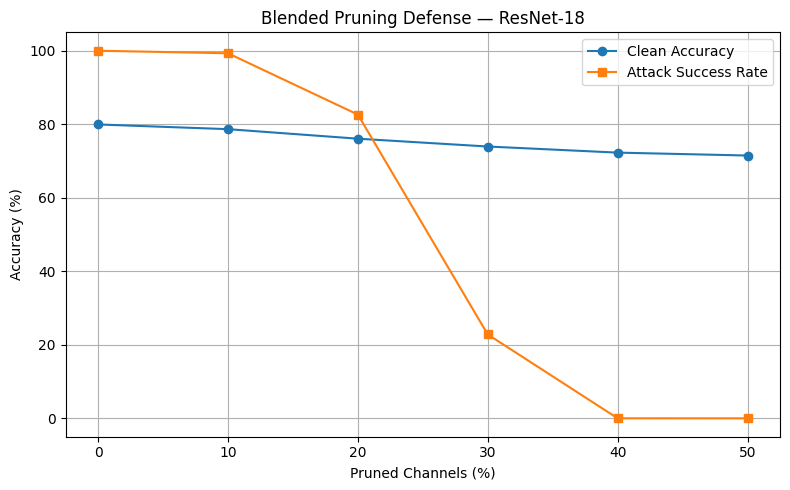

In [56]:

import json
import matplotlib.pyplot as plt

PRUNE_RATES = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
blended_pruning_results = []

for rate in PRUNE_RATES:
    num_pruned = int(
        len(sorted_channels_blended) * rate
    )

    mask = torch.ones(
        len(sorted_channels_blended),
        device=device
    )
    mask[sorted_channels_blended[:num_pruned]] = 0

    # Temporarily mask the final residual stage
    def pruning_hook(module, inputs, output, m=mask):
        return output * m.view(1, -1, 1, 1)

    hook = model_blended_prune.layer4.register_forward_hook(
        pruning_hook
    )

    try:
        ca = evaluate_accuracy(
            model_blended_prune, clean_test_loader
        )

        successes = 0
        total = 0

        model_blended_prune.eval()

        with torch.no_grad():
            for batch_idx, (images, _) in enumerate(
                blended_test_loader
            ):
                start = batch_idx * 128
                end = start + len(images)

                original_labels = torch.tensor(
                    test_dataset.targets[start:end]
                )
                valid = original_labels != 0
                images = images[valid].to(device)

                if images.size(0) == 0:
                    continue

                predictions = model_blended_prune(
                    images
                ).argmax(1)

                successes += (
                    predictions == 0
                ).sum().item()
                total += images.size(0)

        assert total == 9000
        asr = 100.0 * successes / total

        blended_pruning_results.append({
            "prune_rate": rate,
            "clean_accuracy": ca,
            "attack_success_rate": asr,
            "successful_attacks": successes
        })

        print(
            f"Pruning: {rate*100:4.0f}% | "
            f"CA: {ca:.2f}% | "
            f"ASR: {asr:.2f}%"
        )
    finally:
        hook.remove()

# Save results
with open(
    defense_dir / "blended_pruning_results.json", "w"
) as f:
    json.dump(blended_pruning_results, f, indent=4)

# Plot
rates = [r["prune_rate"] * 100
         for r in blended_pruning_results]
ca_values = [r["clean_accuracy"]
             for r in blended_pruning_results]
asr_values = [r["attack_success_rate"]
              for r in blended_pruning_results]

plt.figure(figsize=(8, 5))
plt.plot(rates, ca_values, marker="o",
         label="Clean Accuracy")
plt.plot(rates, asr_values, marker="s",
         label="Attack Success Rate")

plt.xlabel("Pruned Channels (%)")
plt.ylabel("Accuracy (%)")
plt.title("Blended Pruning Defense — ResNet-18")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    defense_dir / "blended_pruning_curve.png",
    dpi=300
)
plt.show()


#Step 3 — Save the Blended pruning configuration

In [57]:

import torch
import json
from pathlib import Path

defense_dir = Path("/content/defense_results")
defense_dir.mkdir(parents=True, exist_ok=True)

selected_rate = 0.40
num_channels = len(sorted_channels_blended)
num_pruned = int(num_channels * selected_rate)

# Create the selected channel mask
selected_mask = torch.ones(num_channels)

selected_mask[
    sorted_channels_blended[:num_pruned].cpu()
] = 0

# Save the mask and its configuration
save_path = defense_dir / "blended_pruning_40pct.pth"

torch.save({
    "attack": "Blended",
    "prune_rate": selected_rate,
    "layer": "layer4",
    "channel_mask": selected_mask,
    "source_checkpoint": "blended_resnet18.pth"
}, save_path)

# Save exact evaluation results
selected_result = next(
    r for r in blended_pruning_results
    if abs(r["prune_rate"] - selected_rate) < 1e-8
)

with open(
    defense_dir / "blended_pruning_selected.json", "w"
) as f:
    json.dump(selected_result, f, indent=4)

print("Blended pruning configuration saved!")
print("Pruned channels:", num_pruned)
print("Clean Accuracy:", selected_result["clean_accuracy"])
print("ASR:", selected_result["attack_success_rate"])
print("Checkpoint:", save_path)


Blended pruning configuration saved!
Pruned channels: 204
Clean Accuracy: 72.28
ASR: 0.011111111111111112
Checkpoint: /content/defense_results/blended_pruning_40pct.pth


#Step 4 — Fine-tune the LabelConsistent model

In [58]:

import random
import torch
import torch.nn as nn
import torch.optim as optim
from pathlib import Path
from torchvision import models
from torch.utils.data import DataLoader, Subset

defense_dir = Path("/content/defense_results")
defense_dir.mkdir(parents=True, exist_ok=True)

# Recreate ResNet-18 architecture
model_label_ft = models.resnet18(weights=None)
model_label_ft.conv1 = nn.Conv2d(
    3, 64, kernel_size=3, stride=1,
    padding=1, bias=False
)
model_label_ft.maxpool = nn.Identity()
model_label_ft.fc = nn.Linear(
    model_label_ft.fc.in_features, 10
)

# Load ORIGINAL LabelConsistent checkpoint
original_label_state = torch.load(
    "/content/labelconsistent_results/labelconsistent_resnet18.pth",
    map_location="cpu",
    weights_only=True
)

model_label_ft.load_state_dict(original_label_state)
model_label_ft = model_label_ft.to(device)

# Same 5,000-image clean training subset
rng = random.Random(42)
indices = rng.sample(range(len(train_dataset)), 5000)

ft_loader = DataLoader(
    Subset(train_dataset, indices),
    batch_size=128,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

optimizer = optim.SGD(
    model_label_ft.parameters(),
    lr=0.001,
    momentum=0.9,
    weight_decay=5e-4
)

criterion = nn.CrossEntropyLoss()

for epoch in range(5):
    model_label_ft.train()
    running_loss = 0.0
    total = 0

    for images, labels in ft_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model_label_ft(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * len(labels)
        total += len(labels)

    ca = evaluate_accuracy(
        model_label_ft, clean_test_loader
    )

    print(
        f"Epoch {epoch+1}/5 | "
        f"Loss: {running_loss/total:.4f} | "
        f"Clean Accuracy: {ca:.2f}%"
    )

# Verify model changed
new_state = model_label_ft.state_dict()

changed = sum(
    not torch.equal(
        original_label_state[name],
        new_state[name].cpu()
    )
    for name in original_label_state
)

assert changed > 0, "Fine-tuning did not modify the model!"

# Save verified checkpoint
torch.save(
    new_state,
    defense_dir / "labelconsistent_finetuned.pth"
)

print("Changed tensors:", changed)
print("LabelConsistent fine-tuning checkpoint saved!")


Epoch 1/5 | Loss: 0.0035 | Clean Accuracy: 80.34%
Epoch 2/5 | Loss: 0.0024 | Clean Accuracy: 80.05%
Epoch 3/5 | Loss: 0.0029 | Clean Accuracy: 80.12%
Epoch 4/5 | Loss: 0.0061 | Clean Accuracy: 79.73%
Epoch 5/5 | Loss: 0.0025 | Clean Accuracy: 79.60%
Changed tensors: 122
LabelConsistent fine-tuning checkpoint saved!


#Step 5 — Evaluate LabelConsistent after fine-tuning

In [59]:

import json
import torch

# Reload verified fine-tuned checkpoint
model_label_ft.load_state_dict(
    torch.load(
        defense_dir / "labelconsistent_finetuned.pth",
        map_location=device,
        weights_only=True
    )
)

model_label_ft.eval()

# Clean accuracy
ft_label_ca = evaluate_accuracy(
    model_label_ft, clean_test_loader
)

# Attack success rate
successes = 0
total = 0

with torch.no_grad():
    for batch_idx, (images, _) in enumerate(
        label_test_loader
    ):
        start = batch_idx * 128
        end = start + len(images)

        original_labels = torch.tensor(
            test_dataset.targets[start:end]
        )

        mask = original_labels != 0
        images = images[mask].to(device)

        if images.size(0) == 0:
            continue

        predictions = model_label_ft(images).argmax(1)

        successes += (predictions == 0).sum().item()
        total += len(images)

assert total == 9000

ft_label_asr = 100.0 * successes / total

print("=" * 45)
print("LabelConsistent Fine-Tuning Defense")
print("=" * 45)
print("Original CA:  80.50%")
print(f"Defended CA:  {ft_label_ca:.2f}%")
print("Original ASR: 53.94%")
print(f"Defended ASR: {ft_label_asr:.2f}%")
print(f"ASR Reduction: {53.94 - ft_label_asr:.2f} pp")
print("=" * 45)

with open(
    defense_dir / "labelconsistent_finetuning_results.json", "w"
) as f:
    json.dump({
        "clean_accuracy_before": 80.50,
        "clean_accuracy_after": ft_label_ca,
        "asr_before": 53.94,
        "asr_after": ft_label_asr,
        "finetuning_epochs": 5,
        "clean_training_samples": 5000,
        "successful_attacks": successes,
        "total_attack_samples": total
    }, f, indent=4)

print("Results saved successfully!")


LabelConsistent Fine-Tuning Defense
Original CA:  80.50%
Defended CA:  79.60%
Original ASR: 53.94%
Defended ASR: 61.29%
ASR Reduction: -7.35 pp
Results saved successfully!


#Task 3 — LabelConsistent Pruning Defense

In [60]:

import random
import torch
import torch.nn as nn
from pathlib import Path
from torchvision import models
from torch.utils.data import DataLoader, Subset

defense_dir = Path("/content/defense_results")
defense_dir.mkdir(parents=True, exist_ok=True)

# Load ORIGINAL LabelConsistent checkpoint
model_label_prune = models.resnet18(weights=None)
model_label_prune.conv1 = nn.Conv2d(
    3, 64, kernel_size=3, stride=1,
    padding=1, bias=False
)
model_label_prune.maxpool = nn.Identity()
model_label_prune.fc = nn.Linear(
    model_label_prune.fc.in_features, 10
)

model_label_prune.load_state_dict(
    torch.load(
        "/content/labelconsistent_results/labelconsistent_resnet18.pth",
        map_location="cpu",
        weights_only=True
    )
)

model_label_prune = model_label_prune.to(device)
model_label_prune.eval()

# Same 5,000 clean calibration images
rng = random.Random(42)
calibration_indices = rng.sample(
    range(len(train_dataset)), 5000
)

calibration_loader = DataLoader(
    Subset(train_dataset, calibration_indices),
    batch_size=128,
    shuffle=False,
    num_workers=2
)

# Measure mean channel activations
activation_sum_label = None
sample_count_label = 0

def label_activation_hook(module, inputs, output):
    global activation_sum_label, sample_count_label

    values = output.detach().mean(dim=(2, 3))
    batch_sum = values.sum(dim=0)

    if activation_sum_label is None:
        activation_sum_label = torch.zeros_like(batch_sum)

    activation_sum_label += batch_sum
    sample_count_label += values.size(0)

handle = model_label_prune.layer4.register_forward_hook(
    label_activation_hook
)

try:
    with torch.no_grad():
        for images, _ in calibration_loader:
            model_label_prune(images.to(device))
finally:
    handle.remove()

mean_activation_label = (
    activation_sum_label / sample_count_label
)
sorted_channels_label = torch.argsort(
    mean_activation_label
)

print("Calibration samples:", sample_count_label)
print("Channels:", len(sorted_channels_label))
print("LabelConsistent calibration completed!")


Calibration samples: 5000
Channels: 512
LabelConsistent calibration completed!


#Step 2 — Evaluate all pruning rates

Pruning:    0% | CA: 80.50% | ASR: 53.94%
Pruning:   10% | CA: 80.20% | ASR: 50.76%
Pruning:   20% | CA: 80.13% | ASR: 43.80%
Pruning:   30% | CA: 79.45% | ASR: 39.04%
Pruning:   40% | CA: 77.34% | ASR: 25.43%
Pruning:   50% | CA: 74.01% | ASR: 14.90%


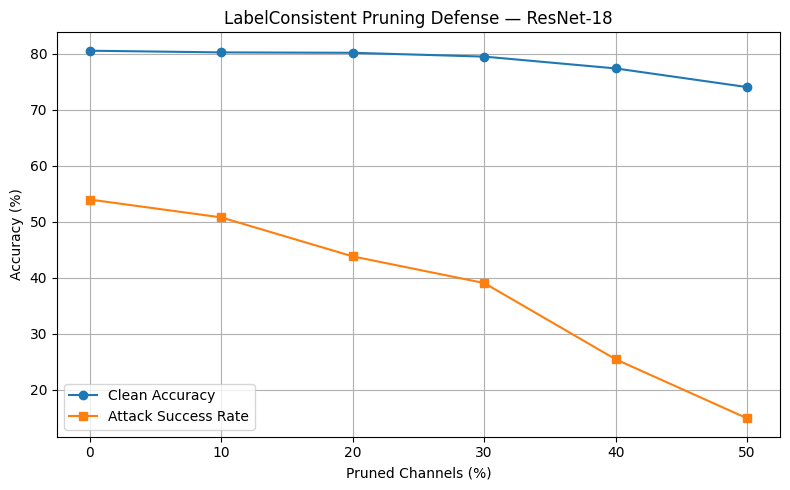

In [61]:

import json
import matplotlib.pyplot as plt

PRUNE_RATES = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
label_pruning_results = []

for rate in PRUNE_RATES:
    n_pruned = int(len(sorted_channels_label) * rate)

    mask = torch.ones(
        len(sorted_channels_label), device=device
    )

    if n_pruned > 0:
        mask[sorted_channels_label[:n_pruned]] = 0

    def pruning_hook(module, inputs, output, m=mask):
        return output * m.view(1, -1, 1, 1)

    hook = model_label_prune.layer4.register_forward_hook(
        pruning_hook
    )

    try:
        ca = evaluate_accuracy(
            model_label_prune, clean_test_loader
        )

        successes = 0
        total = 0

        model_label_prune.eval()

        with torch.no_grad():
            for batch_idx, (images, _) in enumerate(
                label_test_loader
            ):
                start = batch_idx * 128
                end = start + len(images)

                original_labels = torch.tensor(
                    test_dataset.targets[start:end]
                )

                valid = original_labels != 0
                images = images[valid].to(device)

                if len(images) == 0:
                    continue

                predictions = model_label_prune(
                    images
                ).argmax(1)

                successes += (
                    predictions == 0
                ).sum().item()
                total += images.size(0)

        assert total == 9000
        asr = 100.0 * successes / total

        label_pruning_results.append({
            "prune_rate": rate,
            "clean_accuracy": ca,
            "attack_success_rate": asr,
            "successful_attacks": successes
        })

        print(
            f"Pruning: {rate*100:4.0f}% | "
            f"CA: {ca:.2f}% | "
            f"ASR: {asr:.2f}%"
        )
    finally:
        hook.remove()

# Save numerical results
with open(
    defense_dir / "labelconsistent_pruning_results.json",
    "w"
) as f:
    json.dump(label_pruning_results, f, indent=4)

# Plot
rates = [r["prune_rate"] * 100
         for r in label_pruning_results]
ca_values = [r["clean_accuracy"]
             for r in label_pruning_results]
asr_values = [r["attack_success_rate"]
              for r in label_pruning_results]

plt.figure(figsize=(8, 5))
plt.plot(rates, ca_values, marker="o",
         label="Clean Accuracy")
plt.plot(rates, asr_values, marker="s",
         label="Attack Success Rate")

plt.xlabel("Pruned Channels (%)")
plt.ylabel("Accuracy (%)")
plt.title("LabelConsistent Pruning Defense — ResNet-18")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    defense_dir / "labelconsistent_pruning_curve.png",
    dpi=300
)
plt.show()


#Step 3 — Select and save the pruning configuration

In [62]:

import torch
import json
from pathlib import Path

defense_dir = Path("/content/defense_results")
defense_dir.mkdir(parents=True, exist_ok=True)

selected_rate = 0.40
num_channels = len(sorted_channels_label)
num_pruned = int(num_channels * selected_rate)

# Construct channel mask
selected_mask = torch.ones(num_channels)

selected_mask[
    sorted_channels_label[:num_pruned].cpu()
] = 0

# Save pruning configuration
save_path = defense_dir / "labelconsistent_pruning_40pct.pth"

torch.save({
    "attack": "LabelConsistent",
    "prune_rate": selected_rate,
    "layer": "layer4",
    "channel_mask": selected_mask,
    "source_checkpoint": "labelconsistent_resnet18.pth"
}, save_path)

# Save selected evaluation results
selected_result = next(
    r for r in label_pruning_results
    if abs(r["prune_rate"] - selected_rate) < 1e-8
)

with open(
    defense_dir / "labelconsistent_pruning_selected.json", "w"
) as f:
    json.dump(selected_result, f, indent=4)

print("LabelConsistent pruning configuration saved!")
print("Pruned channels:", num_pruned)
print("Clean Accuracy:", selected_result["clean_accuracy"])
print("Attack Success Rate:", selected_result["attack_success_rate"])
print("Saved:", save_path)


LabelConsistent pruning configuration saved!
Pruned channels: 204
Clean Accuracy: 77.34
Attack Success Rate: 25.433333333333334
Saved: /content/defense_results/labelconsistent_pruning_40pct.pth


In [1]:

from pathlib import Path
import zipfile

folders = [
    Path("/content/badnets_results"),
    Path("/content/blended_results"),
    Path("/content/labelconsistent_results"),
    Path("/content/defense_results")
]

zip_path = Path("/content/ECE4_Lab3_Report_Figures.zip")

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as archive:
    for folder in folders:
        if not folder.exists():
            print("Missing folder:", folder)
            continue

        for file in folder.rglob("*"):
            if file.is_file() and file.suffix.lower() in [
                ".png", ".jpg", ".jpeg", ".json"
            ]:
                archive.write(
                    file,
                    arcname=str(file.relative_to("/content"))
                )
                print("Added:", file.name)

print("\nCreated:", zip_path)

from google.colab import files
files.download(str(zip_path))


Missing folder: /content/badnets_results
Missing folder: /content/blended_results
Missing folder: /content/labelconsistent_results
Missing folder: /content/defense_results

Created: /content/ECE4_Lab3_Report_Figures.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>